<a href="https://colab.research.google.com/github/SalehinShan/smart-service-complaint-understanding/blob/main/slscData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install pandas openpyxl scikit-learn


In [2]:

import os

print(os.listdir("/content"))


['.config', 'BanglaPSG_1000_Complaints_Translated.xlsx', '750complaint_dialect - New_Dialect_Complaints_250_Set3.csv', 'sample_data']


In [3]:
import pandas as pd

file_path = '/content/BanglaPSG_1000_Complaints_Translated.xlsx'

# Load and inspect sheets/data
xl = pd.ExcelFile(file_path)
print("Sheet names:", xl.sheet_names)

df_variants = pd.read_excel(file_path)
print("Dataset Shape:", df_variants.shape)
print("\nColumns:")
print(df_variants.columns.tolist())

print("\nFirst 3 rows:")
display(df_variants.head(3))

print("\nMissing values per column:")
print(df_variants.isnull().sum())

Sheet names: ['Complaints_Translated', 'Summary']
Dataset Shape: (1000, 9)

Columns:
['Sample ID', 'Original No.', 'Category', 'Severity', 'Original Complaint (Bangla)', 'Banglish', 'English', 'Code-Mixed', 'Slang']

First 3 rows:


,Sample ID,Original No.,Category,Severity,Original Complaint (Bangla),Banglish,English,Code-Mixed,Slang
0,1,1642,Waste,Low,সানকীপাড়া নতুন পল্লী এলাকায় ময়লাবাহী গাড়ী সপ্ত...,Sankipara Notun Polli elakay moylabahi gari so...,The garbage truck doesn't come more than twice...,Sankipara Notun Polli area তে garbage truck we...,সানকীপাড়া নতুন পল্লীতে ময়লার গাড়ি হপ্তায় দ...
1,2,1055,Healthcare,High,ইবনে সিনা হাসপাতালের ভুল আলটার কারনে আমার বাচ্...,Ibne Sina hospital er bhul ultra-r karone amar...,My baby died because of a wrong ultrasound at ...,Ibne Sina Hospital এর wrong ultrasound report ...,ইবনে সিনার ভুয়া আলট্রার জন্য আমার বাচ্চাটা মই...
2,3,1485,Food,Medium,"ঢাকার, ডেমরা এলাকার স্টাফকোয়াটার এরিয়াতে অনে...",Dhakar Demra elakar Staff Quarter area-te onek...,There are many restaurants and food courts in ...,Dhaka-র Demra-র Staff Quarter area তে অনেক res...,ডেমরার স্টাফ কোয়াটারে হুদাই রেস্টুরেন্ট আর ফু...



Missing values per column:
Sample ID                      0
Original No.                   0
Category                       0
Severity                       0
Original Complaint (Bangla)    0
Banglish                       0
English                        0
Code-Mixed                     0
Slang                          0
dtype: int64


### Training and Evaluation strictly on the 1,000 Translated Complaints
We will partition the 1,000 complaints into 80% train and 20% test splits. The training set will be augmented by flattening all five columns (`Original Complaint (Bangla)`, `Banglish`, `English`, `Code-Mixed`, and `Slang`) so that the TF-IDF Vectorizer learns a multi-script vocabulary.

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the 1,000 Translated Complaints
file_path = '/content/BanglaPSG_1000_Complaints_Translated.xlsx'
df_new = pd.read_excel(file_path)

# Normalize categories
df_new['Category'] = df_new['Category'].astype(str).str.strip()

# 2. Stratified train/test split (80/20) at the row level
train_idx, test_idx = train_test_split(
    df_new.index,
    test_size=0.20,
    random_state=42,
    stratify=df_new['Category']
)

train_df = df_new.loc[train_idx].copy()
test_df = df_new.loc[test_idx].copy()

# 3. Augment Training Set by flattening the 5 text columns
augmented_train_records = []
eval_cols = {
    'Original Complaint (Bangla)': 'Original Complaint (Bangla)',
    'Banglish': 'Banglish',
    'English': 'English',
    'Code-Mixed': 'Code-Mixed',
    'Slang': 'Slang'
}

for idx, row in train_df.iterrows():
    category = row['Category']
    for lang_label, col_name in eval_cols.items():
        text_val = str(row[col_name]).strip()
        if text_val:
            augmented_train_records.append({
                'Text': text_val,
                'Category': category
            })

df_train_augmented = pd.DataFrame(augmented_train_records)
print(f"Original Train Rows: {len(train_df)}")
print(f"Augmented Train Samples (5 variants flattened): {len(df_train_augmented)}")
print(f"Test Rows: {len(test_df)}")

# 4. Define and Train the new Multilingual SVM Pipeline
multilingual_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=30000)),
    ('clf', LinearSVC(C=1.0, random_state=42, class_weight='balanced'))
])

multilingual_pipeline.fit(df_train_augmented['Text'], df_train_augmented['Category'])
print("\nMultilingual Pipeline Successfully Trained!")

# Save this new model
joblib.dump(multilingual_pipeline, '/content/multilingual_grievance_svm_pipeline.pkl')
print("Saved new model to /content/multilingual_grievance_svm_pipeline.pkl")

Original Train Rows: 800
Augmented Train Samples (5 variants flattened): 4000
Test Rows: 200

Multilingual Pipeline Successfully Trained!
Saved new model to /content/multilingual_grievance_svm_pipeline.pkl


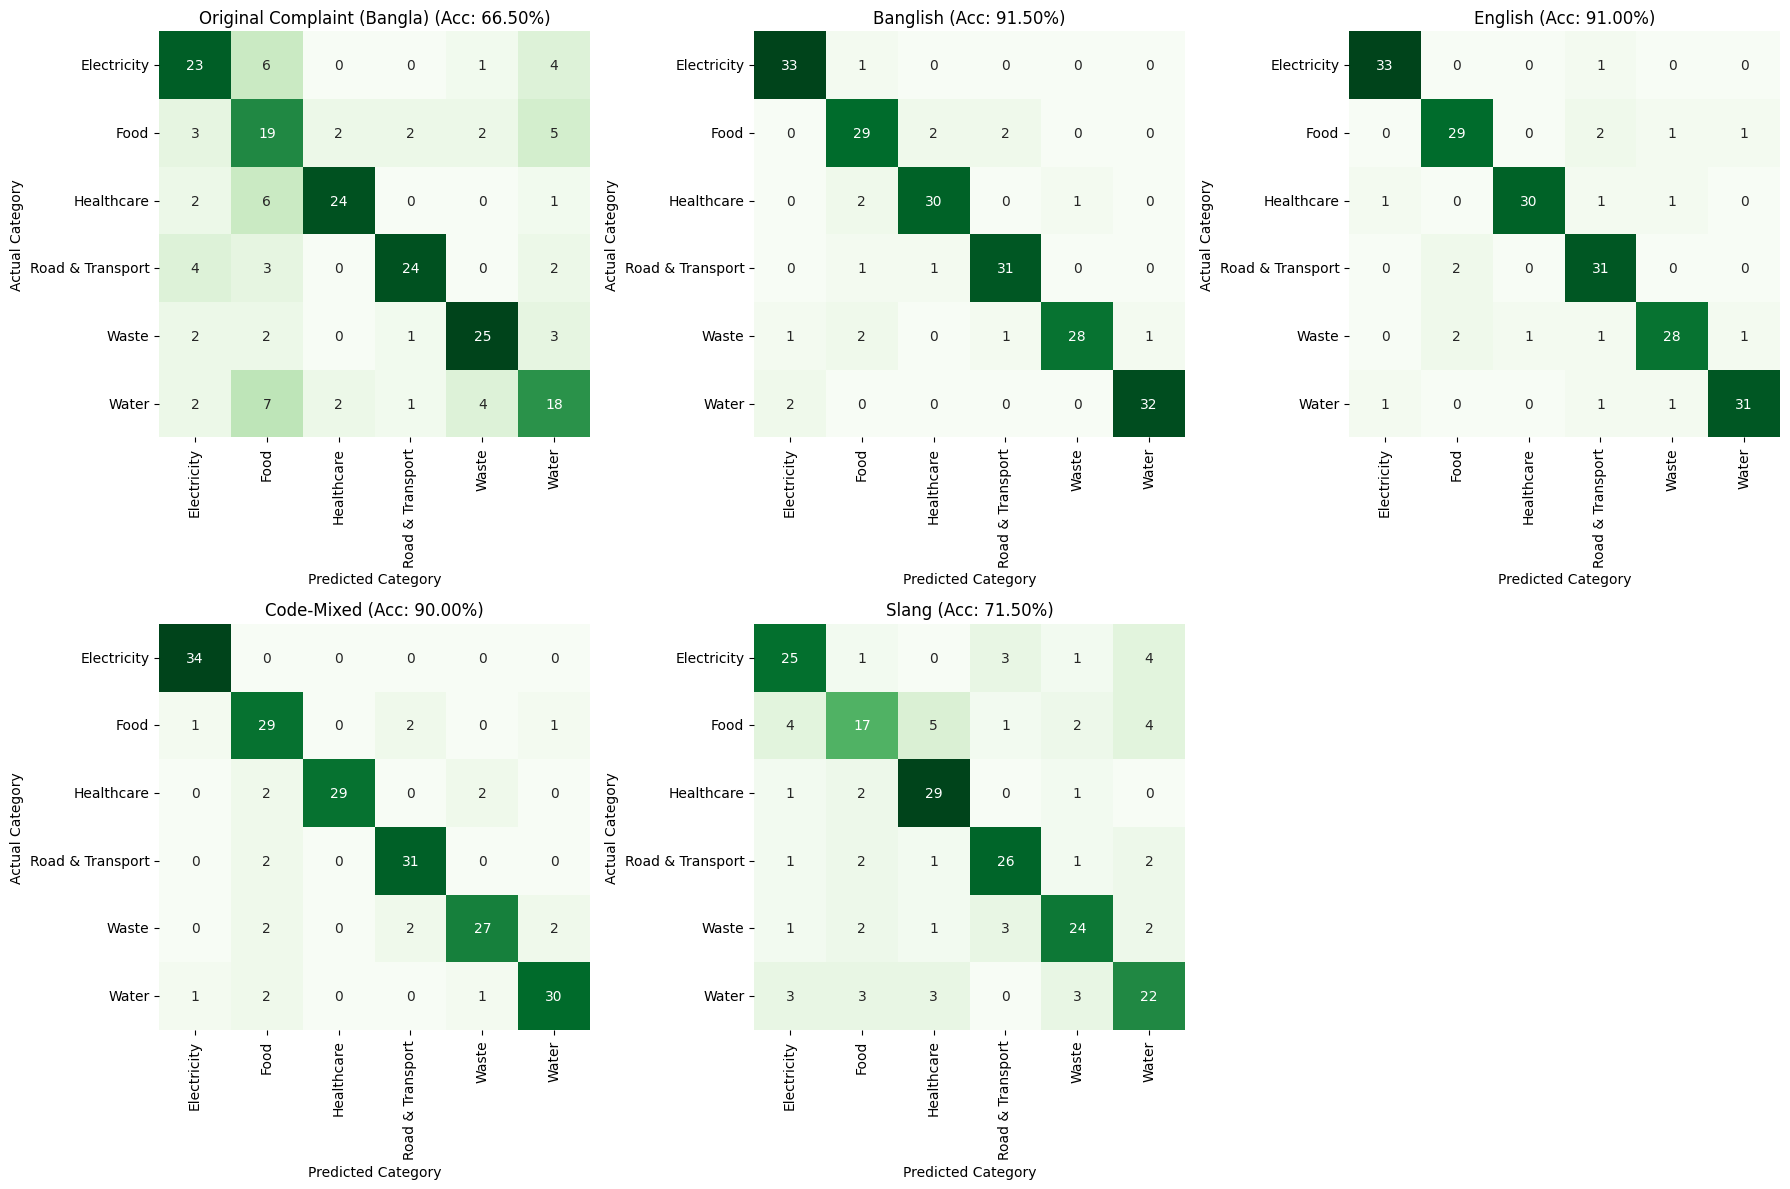

=== NEW ROBUSTNESS SUMMARY ON TEST SPLIT (200 RECS) ===
Original Complaint (Bangla)    | Accuracy: 0.6650
Banglish                       | Accuracy: 0.9150
English                        | Accuracy: 0.9100
Code-Mixed                     | Accuracy: 0.9000
Slang                          | Accuracy: 0.7150


In [5]:
# 5. Evaluate the Multilingual model on the Test Set (200 records) across all 5 variants
y_true_test = test_df['Category'].astype(str).str.strip()
classes = multilingual_pipeline.classes_

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

new_results = {}

for idx, (label, col_name) in enumerate(eval_cols.items()):
    X_test_variant = test_df[col_name].astype(str).str.strip()
    y_pred_variant = multilingual_pipeline.predict(X_test_variant)

    acc = accuracy_score(y_true_test, y_pred_variant)
    new_results[label] = acc

    cm = confusion_matrix(y_true_test, y_pred_variant, labels=classes)

    sns.heatmap(cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes,
                cmap='Greens', ax=axes[idx], cbar=False)
    axes[idx].set_title(f"{label} (Acc: {acc:.2%})")
    axes[idx].set_ylabel('Actual Category')
    axes[idx].set_xlabel('Predicted Category')

axes[5].axis('off')
plt.tight_layout()
plt.show()

print("=== NEW ROBUSTNESS SUMMARY ON TEST SPLIT (200 RECS) ===")
for label, acc in new_results.items():
    print(f"{label:<30} | Accuracy: {acc:.4f}")

In [6]:
import joblib
import pandas as pd
from sklearn.metrics import classification_report

# Load dataset and pipeline
file_path = '/content/BanglaPSG_1000_Complaints_Translated.xlsx'
df_new = pd.read_excel(file_path)
multilingual_pipeline = joblib.load('/content/multilingual_grievance_svm_pipeline.pkl')

# Isolate the identical 20% test split index used for validation
from sklearn.model_selection import train_test_split
df_new['Category'] = df_new['Category'].astype(str).str.strip()
_, test_idx = train_test_split(
    df_new.index,
    test_size=0.20,
    random_state=42,
    stratify=df_new['Category']
)
test_df = df_new.loc[test_idx]
y_true_test = test_df['Category']

eval_cols = {
    'Original Complaint (Bangla)': 'Original Complaint (Bangla)',
    'Banglish': 'Banglish',
    'English': 'English',
    'Code-Mixed': 'Code-Mixed',
    'Slang': 'Slang'
}

# Generate and print a comprehensive report for each variant
for label, col_name in eval_cols.items():
    print(f"\n{'='*20} {label.upper()} CLASSIFICATION REPORT {'='*20}")
    X_test_variant = test_df[col_name].astype(str).str.strip()
    y_pred_variant = multilingual_pipeline.predict(X_test_variant)
    print(classification_report(y_true_test, y_pred_variant, zero_division=0))


==================== ORIGINAL COMPLAINT (BANGLA) CLASSIFICATION REPORT ====================
                  precision    recall  f1-score   support

     Electricity       0.64      0.68      0.66        34
            Food       0.44      0.58      0.50        33
      Healthcare       0.86      0.73      0.79        33
Road & Transport       0.86      0.73      0.79        33
           Waste       0.78      0.76      0.77        33
           Water       0.55      0.53      0.54        34

        accuracy                           0.67       200
       macro avg       0.69      0.67      0.67       200
    weighted avg       0.69      0.67      0.67       200


==================== BANGLISH CLASSIFICATION REPORT ====================
                  precision    recall  f1-score   support

     Electricity       0.92      0.97      0.94        34
            Food       0.83      0.88      0.85        33
      Healthcare       0.91      0.91      0.91        33
Road & Transport 

In [7]:
import numpy as np
import joblib

# Load the pipeline
pipeline = joblib.load('/content/multilingual_grievance_svm_pipeline.pkl')
vectorizer = pipeline.named_steps['tfidf']
classifier = pipeline.named_steps['clf']

# Get feature names
feature_names = np.array(vectorizer.get_feature_names_out())
classes = classifier.classes_

print("=== TOP 10 INFLUENTIAL FEATURES PER CATEGORY ===\n")
for i, class_name in enumerate(classes):
    # For LinearSVC, coef_ has shape (n_classes, n_features)
    coefs = classifier.coef_[i]
    top_indices = np.argsort(coefs)[-10:][::-1]
    top_features = feature_names[top_indices]
    top_weights = coefs[top_indices]

    print(f"Category: {class_name.upper()}")
    print(f"{'Feature':<30} | {'Weight':<10}")
    print("-" * 45)
    for feature, weight in zip(top_features, top_weights):
        print(f"{feature:<30} | {weight:.4f}")
    print("\n" + "="*50 + "\n")

=== TOP 10 INFLUENTIAL FEATURES PER CATEGORY ===

Category: ELECTRICITY
Feature                        | Weight    
---------------------------------------------
electricity                    | 4.0508
biddut                         | 4.0348
পল                             | 3.8935
bidyut                         | 3.1268
meter                          | 2.9219
power                          | 2.7498
palli bidyut                   | 1.9676
palli                          | 1.9676
ইড                             | 1.9652
ইউন                            | 1.9313


Category: FOOD
Feature                        | Weight    
---------------------------------------------
food                           | 3.6911
bhejal                         | 2.4483
তরম                            | 1.9979
khabar                         | 1.9172
bsti                           | 1.7912
ওজন                            | 1.7696
লওয                            | 1.6750
অধ                             | 1.6073
adulteratio

In [8]:
import joblib
import ipywidgets as widgets
from IPython.display import display, clear_output

# 1. Load the trained pipeline
try:
    pipeline = joblib.load('/content/multilingual_grievance_svm_pipeline.pkl')
    print("✅ Multilingual SVM model loaded successfully.")
except Exception as e:
    print(f"❌ Error loading model: {e}")

# 2. Setup interactive widgets
text_input = widgets.Textarea(
    value='',
    placeholder='Type your municipal grievance here...',
    description='Grievance:',
    layout=widgets.Layout(width='80%', height='100px')
)

button = widgets.Button(
    description='Classify Grievance',
    button_style='success',
    tooltip='Click to run inference',
    icon='search'
)

output = widgets.Output()

def on_button_click(b):
    with output:
        clear_output()
        query = text_input.value.strip()
        if not query:
            print("Please enter some text to classify.")
            return

        # Run prediction
        prediction = pipeline.predict([query])[0]

        # Calculate confidence estimate using decision function distances
        decision_values = pipeline.decision_function([query])[0]
        # Display results
        print(f"Raw Query: \"{query}\"\n")
        print(f"Predicted Category: {prediction.upper()}")
        print("-" * 50)
        print("Category Match Confidence Strengths (Higher is better):")
        for cls, score in zip(pipeline.classes_, decision_values):
            indicator = "⭐️" if cls == prediction else "  "
            print(f"{indicator} {cls:<20}: {score:.4f}")

button.on_click(on_button_click)

# 3. Display the Interface
display(widgets.VBox([
    widgets.HTML("<h3>Multilingual Complaints Classifier - Live Testing</h3>"),
    text_input,
    button,
    output
]))

✅ Multilingual SVM model loaded successfully.


**Reasoning**:
Install transformers and torch to prepare for loading the Hugging Face zero-shot classification pipeline.



In [9]:
!pip install transformers torch

### Fixing the Hugging Face Unauthenticated Warning

You can easily resolve this by either silencing the warning or setting up your Hugging Face API token securely.

In [10]:
import os
import logging
import warnings
from google.colab import userdata

# Option A: Silence the Hugging Face warning logger
logging.getLogger("huggingface_hub.utils._http").setLevel(logging.ERROR)

# Option B: Authenticate with a Hugging Face Token (Optional)
# Add a secret named 'HF_TOKEN' via Colab's left sidebar (🔑 icon) first.
try:
    hf_token = userdata.get('HF_TOKEN')
    if hf_token:
        os.environ["HF_TOKEN"] = hf_token
        print("🔑 HF_TOKEN configured successfully.")
    else:
        print("ℹ️ No HF_TOKEN secret found. Warnings will be silenced.")
except Exception as e:
    print("ℹ️ Secrets access skipped or not configured yet.")

🔑 HF_TOKEN configured successfully.


**Reasoning**:
I will initialize the Hugging Face zero-shot classification pipeline using the 'MoritzLaurer/mDeBERTa-v3-base-mnli-xnli' model, detect if GPU is available, and verify its operation with a simple test query.



In [11]:
!pip install "sympy==1.13.3" transformers torch

import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import warnings
warnings.filterwarnings('ignore')

# 1. Check for GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 2. Load model and tokenizer directly
model_name = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
print(f"Loading model: {model_name}...")
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)
print("✅ Model loaded successfully!")

# 3. Define test text and target labels
test_text = "আমাদের এলাকায় পানির কোনো লাইন নাই, আমরা কি খাবো?"
target_labels = ["Electricity", "Food", "Healthcare", "Road & Transport", "Waste", "Water"]

# Format each label into an NLI hypothesis template
# (Standard template used in zero-shot classification)
hypothesis_template = "This text is about {}."
input_pairs = [[test_text, hypothesis_template.format(label)] for label in target_labels]

# 4. Tokenize and run inference manually
inputs = tokenizer(
    input_pairs,
    padding=True,
    truncation=True,
    return_tensors="pt"
).to(device)

with torch.no_grad():
    outputs = model(**inputs)
    logits = outputs.logits

# 5. Extract entailment scores
# For MoritzLaurer/mDeBERTa-v3-base-mnli-xnli, the label mapping is typically:
# 0: Contradiction, 1: Neutral, 2: Entailment (check model card if needed)
# Let's verify standard mDeBERTa/DeBERTa MNLI label IDs:
# Often id2label is {0: 'contradiction', 1: 'neutral', 2: 'entailment'}
entailment_idx = 2
if hasattr(model.config, "id2label"):
    for idx, label in model.config.id2label.items():
        if label.lower() in ["entailment", "entail"]:
            entailment_idx = idx
            break

# Apply softmax across all 3 classes for each label pair, then grab the entailment score
probs = F.softmax(logits, dim=-1)
entailment_scores = probs[:, entailment_idx].cpu().tolist()

# Pair scores with labels and sort
results = sorted(zip(target_labels, entailment_scores), key=lambda x: x[1], reverse=True)
best_label, best_score = results[0]

print(f"\nTest Text: \"{test_text}\"")
print(f"Predicted: {best_label} with score {best_score:.4f}")
print("\nAll scores:")
for label, score in results:
    print(f" - {label}: {score:.4f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.2/6.2 MB 36.8 MB/s  0:00:00
  Attempting uninstall: sympy
    Found existing installation: sympy 1.14.0
    Uninstalling sympy-1.14.0:
      Successfully uninstalled sympy-1.14.0
Using device: cuda
Loading model: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli...


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

✅ Model loaded successfully!

Test Text: "আমাদের এলাকায় পানির কোনো লাইন নাই, আমরা কি খাবো?"
Predicted: Water with score 0.8955

All scores:
 - Water: 0.8955
 - Food: 0.4385
 - Road & Transport: 0.3293
 - Waste: 0.1661
 - Healthcare: 0.0632
 - Electricity: 0.0252


**Reasoning**:
We will run zero-shot inference with mDeBERTa on the 200 test set rows across all 5 language variants and store the predictions in a dictionary.



In [12]:
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tqdm.notebook import tqdm
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# 1. Load dataset and reproduce the identical 20% test split
file_path = '/content/BanglaPSG_1000_Complaints_Translated.xlsx'
df_new = pd.read_excel(file_path)
df_new['Category'] = df_new['Category'].astype(str).str.strip()

_, test_idx = train_test_split(
    df_new.index,
    test_size=0.20,
    random_state=42,
    stratify=df_new['Category']
)
test_df = df_new.loc[test_idx].copy()

# 2. Setup Device, Model, and Tokenizer directly for maximum speed
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model_name = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
print(f"Loading model & tokenizer: {model_name}...")
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)
model.eval() # Set to evaluation mode for inference speedup
print("✅ Model loaded successfully!")

# Identify entailment index from model config
entailment_idx = 2
if hasattr(model.config, "id2label"):
    for idx, label in model.config.id2label.items():
        if label.lower() in ["entailment", "entail"]:
            entailment_idx = idx
            break

# Target categories and template
target_labels = ['Electricity', 'Food', 'Healthcare', 'Road & Transport', 'Waste', 'Water']
hypothesis_template = "This text is about {}."

eval_cols = {
    'Original Complaint (Bangla)': 'Original Complaint (Bangla)',
    'Banglish': 'Banglish',
    'English': 'English',
    'Code-Mixed': 'Code-Mixed',
    'Slang': 'Slang'
}

# 3. Optimized Batched Inference Function
def batch_zero_shot_predict(texts, batch_size=32):
    all_preds = []

    # Pre-construct hypothesis pairs for all texts against all target labels
    # Shape per text: len(target_labels) pairs
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]
        batch_pairs = []

        for text in batch_texts:
            clean_text = text if text and isinstance(text, str) and text.strip() else "Unknown complaint"
            for label in target_labels:
                batch_pairs.append([clean_text, hypothesis_template.format(label)])

        # Tokenize the entire batch at once
        inputs = tokenizer(
            batch_pairs,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad(), torch.cuda.amp.autocast(): # Mixed precision for extra speed on T4
            outputs = model(**inputs)
            logits = outputs.logits

        # Reshape logits back to [batch_size, num_labels, 3] or similar, then softmax
        probs = F.softmax(logits, dim=-1)
        entailment_scores = probs[:, entailment_idx].cpu().numpy()

        # Reshape scores into [len(batch_texts), len(target_labels)]
        entailment_scores = entailment_scores.reshape(len(batch_texts), len(target_labels))

        # Pick the label with the highest entailment score for each text
        best_label_indices = np.argmax(entailment_scores, axis=1)
        for idx in best_label_indices:
            all_preds.append(target_labels[idx])

    return all_preds

# 4. Iterate over the 5 variants using the fast batched method
zero_shot_preds = {}
BATCH_SIZE = 32 # Adjust up (e.g. 64) or down if you hit VRAM limits on T4

for label, col_name in eval_cols.items():
    print(f"\nRunning Fast Batched Inference for: {label}...")
    texts = test_df[col_name].astype(str).tolist()

    # Wrap text generation with a tqdm progress bar over batches
    preds = []
    for i in tqdm(range(0, len(texts), BATCH_SIZE)):
        batch_texts = texts[i:i + BATCH_SIZE]
        batch_preds = batch_zero_shot_predict(batch_texts, batch_size=len(batch_texts))
        preds.extend(batch_preds)

    zero_shot_preds[label] = preds

# Verify predictions shape
print("\n=== ZERO-SHOT INFERENCE COMPLETE ===")
for label, preds in zero_shot_preds.items():
    print(f"{label}: {len(preds)} predictions successfully generated.")

Using device: cuda
Loading model & tokenizer: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

✅ Model loaded successfully!

Running Fast Batched Inference for: Original Complaint (Bangla)...


  0%|          | 0/7 [00:00<?, ?it/s]


Running Fast Batched Inference for: Banglish...


  0%|          | 0/7 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/7 [00:00<?, ?it/s]


Running Fast Batched Inference for: Slang...


  0%|          | 0/7 [00:00<?, ?it/s]


=== ZERO-SHOT INFERENCE COMPLETE ===
Original Complaint (Bangla): 200 predictions successfully generated.
Banglish: 200 predictions successfully generated.
English: 200 predictions successfully generated.
Code-Mixed: 200 predictions successfully generated.
Slang: 200 predictions successfully generated.


## Performance Comparison: Zero-Shot vs. Multilingual SVM

### Subtask:
Compute accuracy, F1-scores, and detailed classification reports for both models across all five language variants.

In [13]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd
import joblib

# Initialize a list to hold consolidated metrics for easy comparison
comparison_metrics = []

# Load the saved multilingual pipeline to resolve the NameError
model_path = '/content/multilingual_grievance_svm_pipeline.pkl'
try:
    multilingual_pipeline = joblib.load(model_path)
    print("✅ Loaded multilingual_pipeline from disk successfully!")
except Exception as e:
    print(f"❌ Could not load pipeline: {e}. Please ensure you trained the model in the previous steps.")

# Ensure we have ground truth aligned
y_true = test_df['Category'].astype(str).str.strip().tolist()

for label, col_name in eval_cols.items():
    # 1. SVM predictions
    X_test_variant = test_df[col_name].astype(str).str.strip()
    y_pred_svm = multilingual_pipeline.predict(X_test_variant)

    # 2. Zero-shot predictions
    y_pred_zs = zero_shot_preds[label]

    # Calculate SVM metrics
    acc_svm = accuracy_score(y_true, y_pred_svm)
    f1_svm = f1_score(y_true, y_pred_svm, average='macro')

    # Calculate Zero-Shot metrics
    acc_zs = accuracy_score(y_true, y_pred_zs)
    f1_zs = f1_score(y_true, y_pred_zs, average='macro')

    comparison_metrics.append({
        'Variant': label,
        'SVM Accuracy': acc_svm,
        'SVM F1-Macro': f1_svm,
        'Zero-Shot Accuracy': acc_zs,
        'Zero-Shot F1-Macro': f1_zs
    })

    # Display detailed classification reports side-by-side/sequentially
    print(f"\n{'='*30} VARIANT: {label.upper()} {'='*30}")
    print("\n--- MULTILINGUAL SVM CLASSIFICATION REPORT ---")
    print(classification_report(y_true, y_pred_svm, zero_division=0))

    print("\n--- ZERO-SHOT MDEBERTA CLASSIFICATION REPORT ---")
    print(classification_report(y_true, y_pred_zs, zero_division=0))

# Convert comparison metrics to DataFrame for rich visualization
df_comparison = pd.DataFrame(comparison_metrics)
display(df_comparison)

✅ Loaded multilingual_pipeline from disk successfully!

============================== VARIANT: ORIGINAL COMPLAINT (BANGLA) ==============================

--- MULTILINGUAL SVM CLASSIFICATION REPORT ---
                  precision    recall  f1-score   support

     Electricity       0.64      0.68      0.66        34
            Food       0.44      0.58      0.50        33
      Healthcare       0.86      0.73      0.79        33
Road & Transport       0.86      0.73      0.79        33
           Waste       0.78      0.76      0.77        33
           Water       0.55      0.53      0.54        34

        accuracy                           0.67       200
       macro avg       0.69      0.67      0.67       200
    weighted avg       0.69      0.67      0.67       200


--- ZERO-SHOT MDEBERTA CLASSIFICATION REPORT ---
                  precision    recall  f1-score   support

     Electricity       0.97      0.82      0.89        34
            Food       0.88      0.64      0.74

,Variant,SVM Accuracy,SVM F1-Macro,Zero-Shot Accuracy,Zero-Shot F1-Macro
0,Original Complaint (Bangla),0.665,0.672910,0.735,0.748166
1,Banglish,0.915,0.914785,0.290,0.291067
2,English,0.910,0.909816,0.740,0.745505
3,Code-Mixed,0.900,0.899986,0.720,0.732397
4,Slang,0.715,0.711710,0.690,0.702985


## Visualize Comparative Analysis

### Subtask:
Generate comparative bar charts showing Accuracy and F1-Macro scores side-by-side for the Supervised Multilingual SVM and the Zero-Shot mDeBERTa model across all 5 language variants.

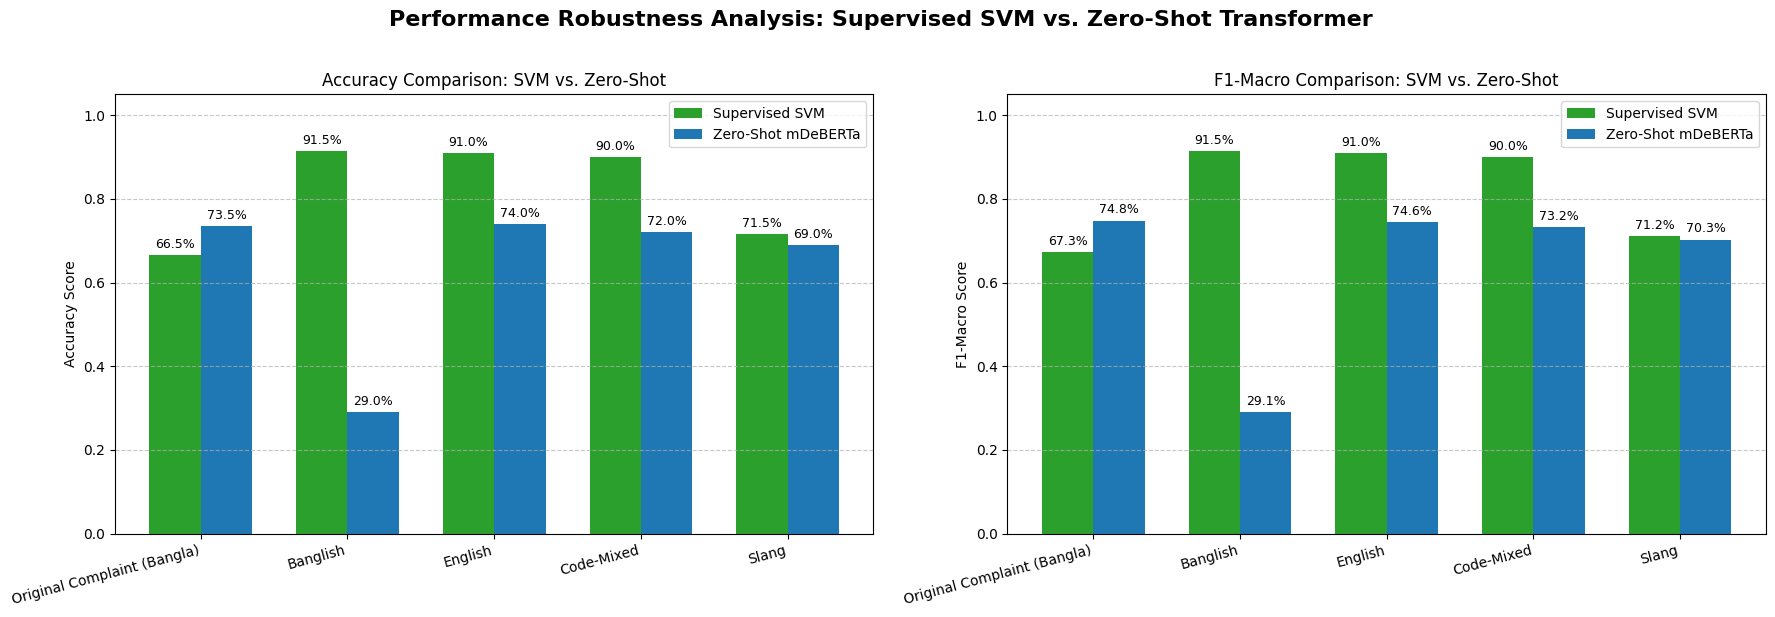

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Extract data from our comparison dataframe
variants = df_comparison['Variant'].tolist()
x = np.arange(len(variants))  # label locations
width = 0.35  # width of the bars

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# 1. Plot Accuracy comparison
rects1_acc = ax1.bar(x - width/2, df_comparison['SVM Accuracy'], width, label='Supervised SVM', color='#2ca02c')
rects2_acc = ax1.bar(x + width/2, df_comparison['Zero-Shot Accuracy'], width, label='Zero-Shot mDeBERTa', color='#1f77b4')

ax1.set_ylabel('Accuracy Score')
ax1.set_title('Accuracy Comparison: SVM vs. Zero-Shot')
ax1.set_xticks(x)
ax1.set_xticklabels(variants, rotation=15, ha='right')
ax1.set_ylim(0, 1.05)
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# Add values on top of bars for Accuracy
def autolabel(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1%}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1_acc, ax1)
autolabel(rects2_acc, ax1)

# 2. Plot F1-Macro comparison
rects1_f1 = ax2.bar(x - width/2, df_comparison['SVM F1-Macro'], width, label='Supervised SVM', color='#2ca02c')
rects2_f1 = ax2.bar(x + width/2, df_comparison['Zero-Shot F1-Macro'], width, label='Zero-Shot mDeBERTa', color='#1f77b4')

ax2.set_ylabel('F1-Macro Score')
ax2.set_title('F1-Macro Comparison: SVM vs. Zero-Shot')
ax2.set_xticks(x)
ax2.set_xticklabels(variants, rotation=15, ha='right')
ax2.set_ylim(0, 1.05)
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.7)

autolabel(rects1_f1, ax2)
autolabel(rects2_f1, ax2)

plt.suptitle('Performance Robustness Analysis: Supervised SVM vs. Zero-Shot Transformer', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

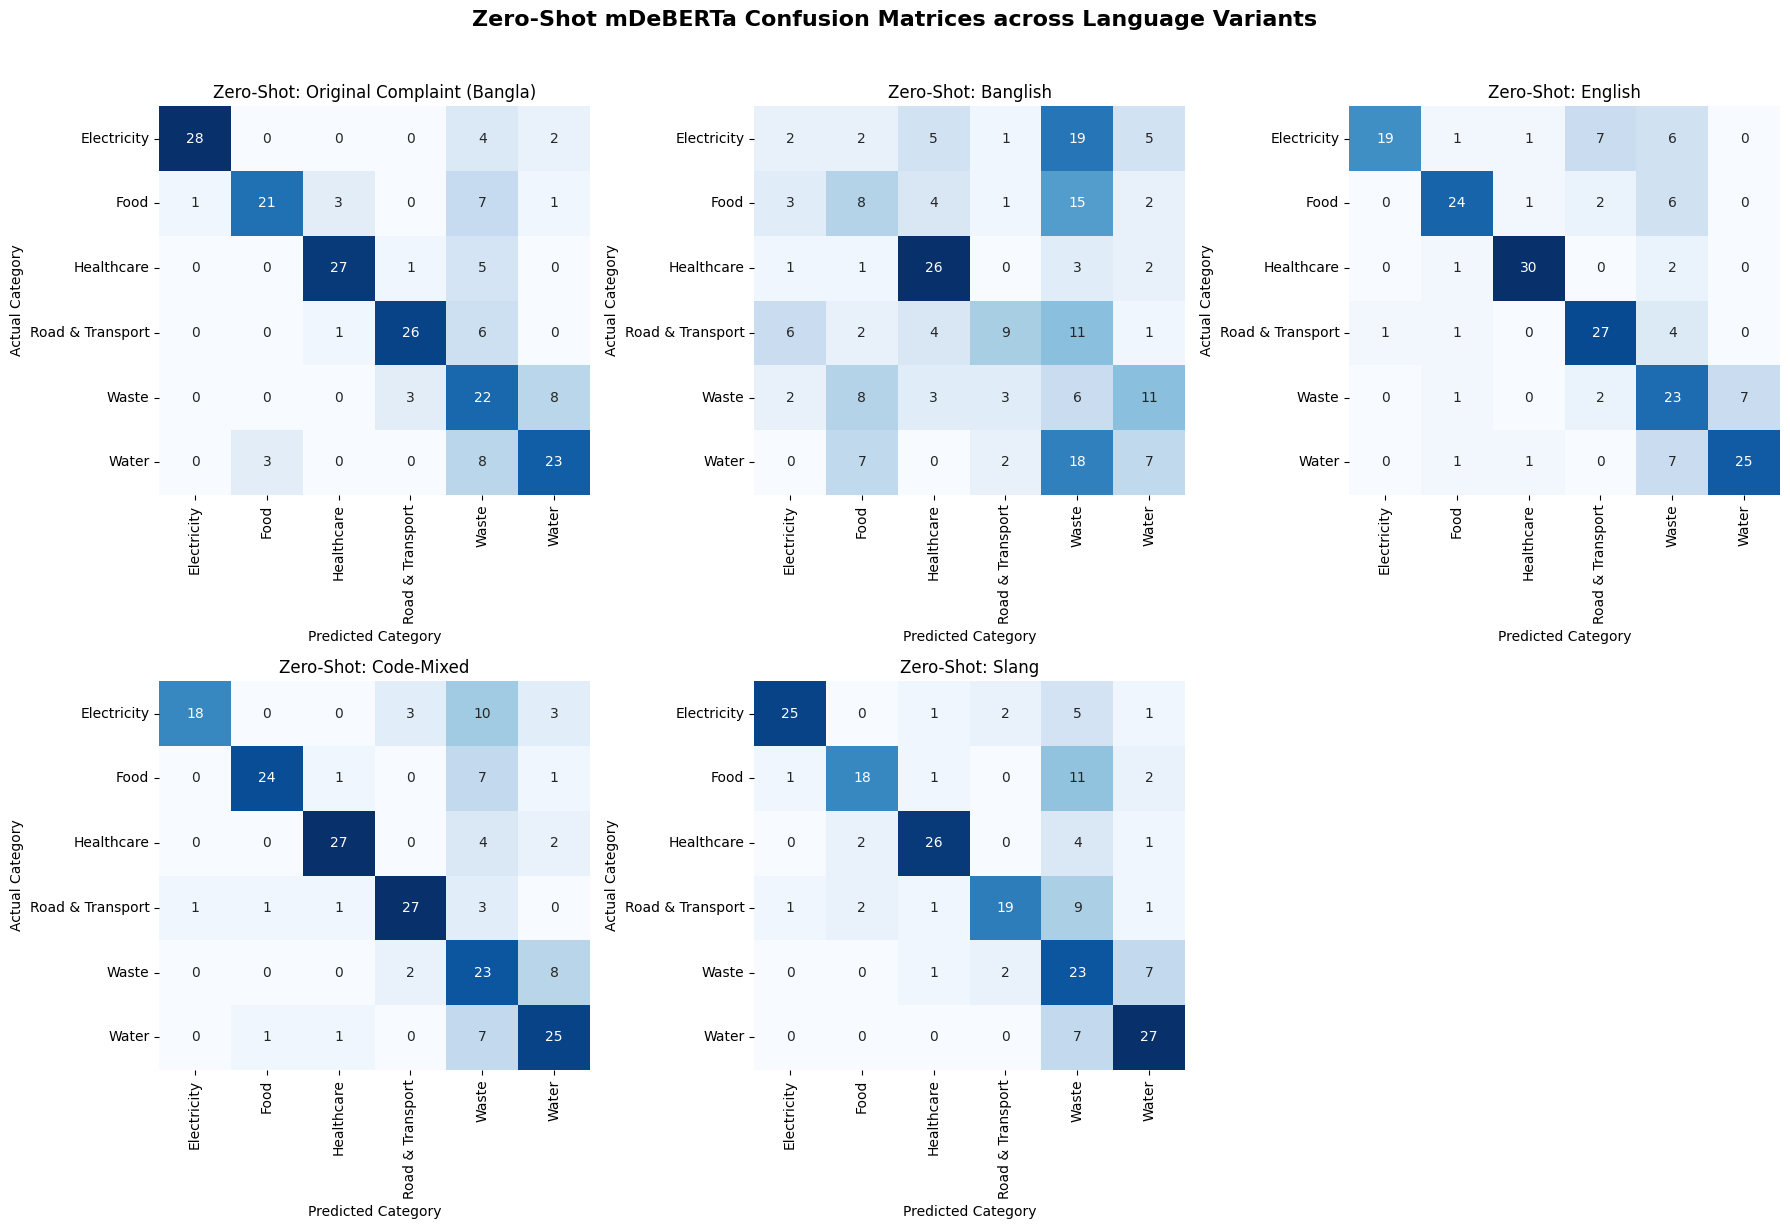

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_true_test = test_df['Category'].astype(str).str.strip()
classes = sorted(list(set(y_true_test)))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, (label, col_name) in enumerate(eval_cols.items()):
    # Get Zero-Shot predictions for the current variant
    y_pred_zs = zero_shot_preds[label]

    # Compute confusion matrix
    cm = confusion_matrix(y_true_test, y_pred_zs, labels=classes)

    # Plot heatmaps
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes,
                cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f"Zero-Shot: {label}")
    axes[idx].set_ylabel('Actual Category')
    axes[idx].set_xlabel('Predicted Category')

# Turn off the empty subplot in the grid
axes[5].axis('off')
plt.suptitle('Zero-Shot mDeBERTa Confusion Matrices across Language Variants', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [16]:
import os
import joblib
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    Trainer,
    TrainingArguments,
)
from datasets import Dataset

# 1. Load dataset from your environment
file_path = "/content/BanglaPSG_1000_Complaints_Translated.xlsx"
df_new = pd.read_excel(file_path)

# Normalize categories
df_new["Category"] = df_new["Category"].astype(str).str.strip()
unique_classes = sorted(df_new["Category"].unique())
label2id = {label: i for i, label in enumerate(unique_classes)}
id2label = {i: label for i, label in enumerate(unique_classes)}

print(f"Detected Categories ({len(unique_classes)}): {unique_classes}")

# 2. Re-create the identical 80/20 train/test split used in your previous baseline
train_idx, test_idx = train_test_split(
    df_new.index, test_size=0.20, random_state=42, stratify=df_new["Category"]
)

train_df = df_new.loc[train_idx].copy()
test_df = df_new.loc[test_idx].copy()

# 3. Augment Training Set by flattening the 5 text variants
eval_cols = {
    "Original Complaint (Bangla)": "Original Complaint (Bangla)",
    "Banglish": "Banglish",
    "English": "English",
    "Code-Mixed": "Code-Mixed",
    "Slang": "Slang",
}

augmented_train_records = []
for idx, row in train_df.iterrows():
    category = row["Category"]
    for lang_label, col_name in eval_cols.items():
        text_val = str(row[col_name]).strip()
        if text_val and text_val.lower() != "nan":
            augmented_train_records.append(
                {"text": text_val, "label": label2id[category]}
            )

df_train_augmented = pd.DataFrame(augmented_train_records)
print(f"Augmented Training Samples (5 variants flattened): {len(df_train_augmented)}")
print(f"Test Set Rows: {len(test_df)}")

# Convert to Hugging Face Dataset objects
train_dataset = Dataset.from_pandas(df_train_augmented)

# Prepare test dataset (using Original Bangla or a specific variant for evaluation)
test_records = []
for idx, row in test_df.iterrows():
    test_records.append(
        {"text": str(row["Original Complaint (Bangla)"]).strip(), "label": label2id[row["Category"]]}
    )
test_dataset = Dataset.from_pandas(pd.DataFrame(test_records))

# 4. Load mDeBERTa Tokenizer and Model
model_name = "microsoft/mdeberta-v3-base"
print(f"\nLoading tokenizer and model: {model_name}...")
tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(unique_classes),
    id2label=id2label,
    label2id=label2id,
)

# 🛠️ FIX: Explicitly cast model weights to float32 to prevent FP16 scaler crash
model = model.to(torch.float32)

# 5. Tokenization function
def tokenize_function(examples):
    return tokenizer(
        examples["text"], padding="max_length", truncation=True, max_length=128
    )

tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_test = test_dataset.map(tokenize_function, batched=True)

# 6. Define evaluation metrics callback for Trainer
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    acc = accuracy_score(labels, preds)
    f1_macro = f1_score(labels, preds, average="macro")
    return {"accuracy": acc, "f1_macro": f1_macro}

# 7. Setup Training Arguments optimized for Google Colab T4/L4 GPUs
training_args = TrainingArguments(
    output_dir="./mdeberta_grievance_results",
    learning_rate=3e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="no",  # Can set to 'epoch' if validation split is provided
    save_strategy="epoch",
    logging_steps=50,
    fp16=torch.cuda.is_available(),  # Safe to use now that model is float32
    load_best_model_at_end=False,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    compute_metrics=compute_metrics,
)

# 8. Fine-tune the model
print("\n🚀 Starting mDeBERTa Fine-Tuning...")
trainer.train()

# Save the fine-tuned model and tokenizer locally
model.save_pretrained("/content/fine_tuned_mdeberta_grievance")
tokenizer.save_pretrained("/content/fine_tuned_mdeberta_grievance")
print(
    "✅ Model successfully fine-tuned and saved to"
    " /content/fine_tuned_mdeberta_grievance"
)

# 9. Evaluate on the Test Set
print("\nEvaluating fine-tuned model on Test Set...")
eval_results = trainer.evaluate(tokenized_test)
print(f"Test Results: {eval_results}")

Detected Categories (6): ['Electricity', 'Food', 'Healthcare', 'Road & Transport', 'Waste', 'Water']
Augmented Training Samples (5 variants flattened): 4000
Test Set Rows: 200

Loading tokenizer and model: microsoft/mdeberta-v3-base...


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.33GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

... (10 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model successfully fine-tuned and saved to /content/fine_tuned_mdeberta_grievance

Evaluating fine-tuned model on Test Set...


Training Loss,Validation Loss,Step,Accuracy,F1 Macro
0.210778,0.331644,750,0.930000,0.929884


Test Results: {'eval_loss': 0.33164435625076294, 'eval_accuracy': 0.93, 'eval_f1_macro': 0.929883666584434}


In [17]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import classification_report, accuracy_score, f1_score
from tqdm.notebook import tqdm
import numpy as np

# 1. Load the fine-tuned model and tokenizer
model_path = "/content/fine_tuned_mdeberta_grievance"
print(f"Loading fine-tuned model from {model_path}...")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path).to(device)
model.eval()
print("✅ Fine-tuned mDeBERTa loaded successfully on device:", device)

# Get mapping dictionaries from config
id2label = model.config.id2label
target_labels = [id2label[i] for i in range(len(id2label))]

# 2. Setup the test dataset variants (reusing test_df from your split)
y_true = test_df['Category'].astype(str).str.strip().tolist()

eval_cols = {
    'Original Complaint (Bangla)': 'Original Complaint (Bangla)',
    'Banglish': 'Banglish',
    'English': 'English',
    'Code-Mixed': 'Code-Mixed',
    'Slang': 'Slang'
}

# 3. Fast Batched Inference Function for mDeBERTa
def predict_batch(texts, batch_size=32):
    all_preds = []
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]
        clean_texts = [str(t) if t and str(t).lower() != 'nan' else "" for t in batch_texts]

        inputs = tokenizer(
            clean_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            outputs = model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)
            preds = torch.argmax(probs, dim=-1).cpu().tolist()

        all_preds.extend([id2label[p] for p in preds])
    return all_preds

# 4. Evaluate across all 5 variants
mdeberta_results = []

for label, col_name in eval_cols.items():
    print(f"\n{'='*20} EVALUATING VARIANT: {label.upper()} {'='*20}")
    texts = test_df[col_name].astype(str).tolist()

    # Run predictions
    y_pred = predict_batch(texts)

    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='macro')

    mdeberta_results.append({
        'Variant': label,
        'mDeBERTa Accuracy': acc,
        'mDeBERTa F1-Macro': f1
    })

    print(classification_report(y_true, y_pred, zero_division=0))

# 5. Summary Comparison Table
df_mdeberta_comp = pd.DataFrame(mdeberta_results)
print("\n=== FINETUNED MDEBERTA PERFORMANCE SUMMARY ===")
display(df_mdeberta_comp)

Loading fine-tuned model from /content/fine_tuned_mdeberta_grievance...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

✅ Fine-tuned mDeBERTa loaded successfully on device: cuda

==================== EVALUATING VARIANT: ORIGINAL COMPLAINT (BANGLA) ====================
                  precision    recall  f1-score   support

     Electricity       0.94      1.00      0.97        34
            Food       0.86      0.94      0.90        33
      Healthcare       0.97      0.94      0.95        33
Road & Transport       0.97      0.91      0.94        33
           Waste       0.97      0.91      0.94        33
           Water       0.91      0.91      0.91        34

        accuracy                           0.94       200
       macro avg       0.94      0.93      0.94       200
    weighted avg       0.94      0.94      0.94       200


==================== EVALUATING VARIANT: BANGLISH ====================
                  precision    recall  f1-score   support

     Electricity       0.89      0.97      0.93        34
            Food       0.59      0.67      0.63        33
      Healthcare     

,Variant,mDeBERTa Accuracy,mDeBERTa F1-Macro
0,Original Complaint (Bangla),0.935,0.935098
1,Banglish,0.755,0.753791
2,English,0.915,0.913486
3,Code-Mixed,0.915,0.913978
4,Slang,0.925,0.924102


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Running batch inference on the 750 dialect complaints dataset...

🎯 Overall Accuracy on 750 Dataset: 0.5947
🎯 Overall Macro F1-Score: 0.5889

=== DIALECT-WISE PERFORMANCE SUMMARY ===


,Dialect Region,Sample Count,Accuracy,Macro F1-Score
0,Barishal,150,0.553333,0.553441
1,Chittagong,150,0.633333,0.630477
2,Mymensingh,150,0.620000,0.618469
3,Noakhali,150,0.626667,0.614157
4,Sylhet,150,0.540000,0.522912


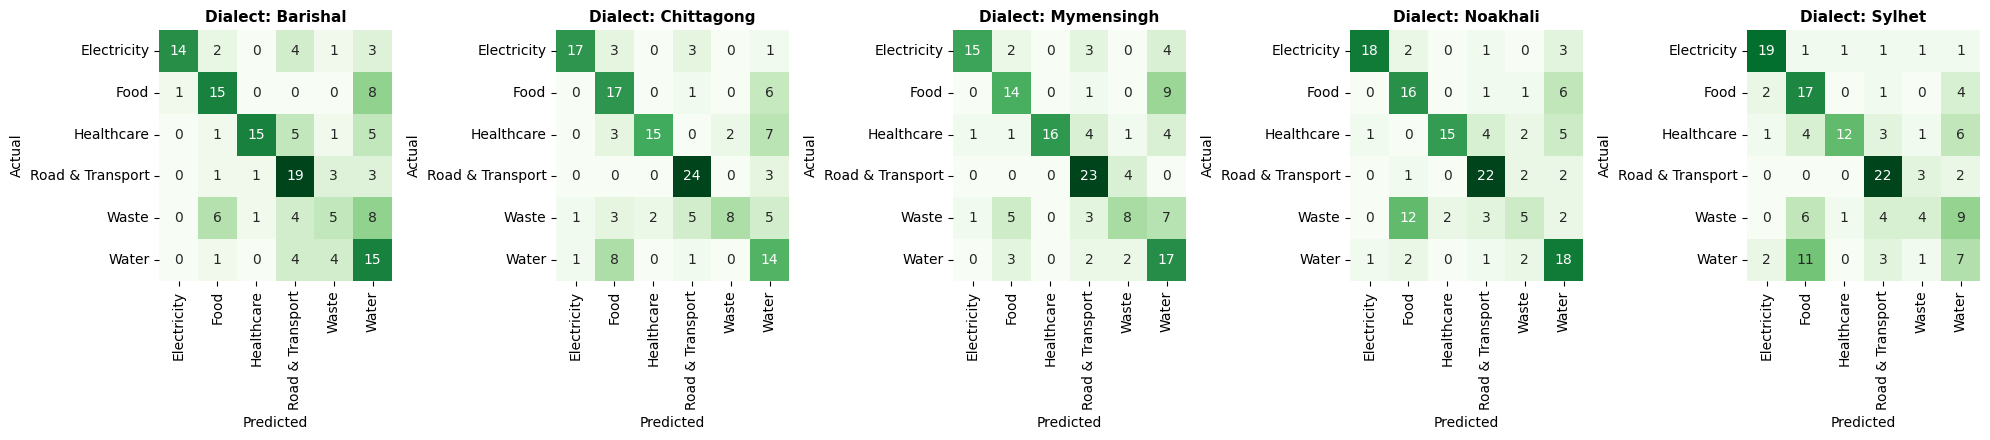


--- Detailed Classification Report ---
                  precision    recall  f1-score   support

     Electricity       0.87      0.69      0.77       120
            Food       0.50      0.66      0.57       120
      Healthcare       0.90      0.54      0.68       135
Road & Transport       0.64      0.81      0.72       135
           Waste       0.49      0.25      0.33       120
           Water       0.39      0.59      0.47       120

        accuracy                           0.59       750
       macro avg       0.63      0.59      0.59       750
    weighted avg       0.64      0.59      0.59       750



In [18]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Load your fine-tuned mDeBERTa model and tokenizer
model_path = "/content/fine_tuned_mdeberta_grievance"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path).to(device)
model.eval()

id2label = model.config.id2label
classes = sorted([id2label[i] for i in id2label.keys()])

# 2. Load the 750 dataset
df_750 = pd.read_csv('/content/750complaint_dialect - New_Dialect_Complaints_250_Set3.csv')
df_750 = df_750.dropna(subset=['Dialect', 'Category']) # Clean any stray empty rows

y_true_all = df_750['Category'].astype(str).str.strip().tolist()
texts = df_750['Complaint (Dialect Banglish)'].astype(str).tolist() # You can change to 'Complaint (Dialect Bangla)' if desired

# 3. Batch inference function
predictions = []
BATCH_SIZE = 32

print("Running batch inference on the 750 dialect complaints dataset...")
for i in range(0, len(texts), BATCH_SIZE):
    batch_texts = texts[i:i + BATCH_SIZE]
    inputs = tokenizer(
        batch_texts,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = F.softmax(outputs.logits, dim=-1)
        preds = torch.argmax(probs, dim=-1).cpu().tolist()

    predictions.extend([id2label[p] for p in preds])

df_750['Predicted_Category'] = predictions

# 4. Compute Overall Metrics
overall_acc = accuracy_score(y_true_all, predictions)
overall_f1 = f1_score(y_true_all, predictions, average='macro')
print(f"\n🎯 Overall Accuracy on 750 Dataset: {overall_acc:.4f}")
print(f"🎯 Overall Macro F1-Score: {overall_f1:.4f}")

# 5. Dialect-Wise Performance Summary Table
regional_metrics = []
dialects = sorted(df_750['Dialect'].unique())

for dialect in dialects:
    sub_df = df_750[df_750['Dialect'] == dialect]
    d_true = sub_df['Category'].astype(str).str.strip().tolist()
    d_pred = sub_df['Predicted_Category'].tolist()

    acc = accuracy_score(d_true, d_pred)
    f1 = f1_score(d_true, d_pred, average='macro')

    regional_metrics.append({
        'Dialect Region': dialect,
        'Sample Count': len(sub_df),
        'Accuracy': acc,
        'Macro F1-Score': f1
    })

df_metrics_summary = pd.DataFrame(regional_metrics)
print("\n=== DIALECT-WISE PERFORMANCE SUMMARY ===")
display(df_metrics_summary)

# 6. Plot Dialect-Wise Side-by-Side Confusion Matrices
fig, axes = plt.subplots(1, len(dialects), figsize=(4 * len(dialects), 4.5))

for idx, dialect in enumerate(dialects):
    sub_df = df_750[df_750['Dialect'] == dialect]
    cm = confusion_matrix(sub_df['Category'], sub_df['Predicted_Category'], labels=classes)

    sns.heatmap(
        cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes,
        cmap='Greens', cbar=False, ax=axes[idx]
    )
    axes[idx].set_title(f"Dialect: {dialect}", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Predicted", fontsize=10)
    axes[idx].set_ylabel("Actual", fontsize=10)
    axes[idx].tick_params(axis='x', rotation=90)
    axes[idx].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

# 7. Detailed Classification Report across all 750 samples
print("\n--- Detailed Classification Report ---")
print(classification_report(y_true_all, predictions, zero_division=0))

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Running inference on 750 dataset (Dialect Bangla)...
Running inference on 750 dataset (Dialect Banglish)...

==================== 750 DATASET PERFORMANCE COMPARISON ====================
Bangla Script   -> Accuracy: 0.7680 | F1-Macro: 0.7636
Banglish Script -> Accuracy: 0.5947 | F1-Macro: 0.5889

--- Classification Report (Banglish Script) ---
                  precision    recall  f1-score   support

     Electricity       0.87      0.69      0.77       120
            Food       0.50      0.66      0.57       120
      Healthcare       0.90      0.54      0.68       135
Road & Transport       0.64      0.81      0.72       135
           Waste       0.49      0.25      0.33       120
           Water       0.39      0.59      0.47       120

        accuracy                           0.59       750
       macro avg       0.63      0.59      0.59       750
    weighted avg       0.64      0.59      0.59       750



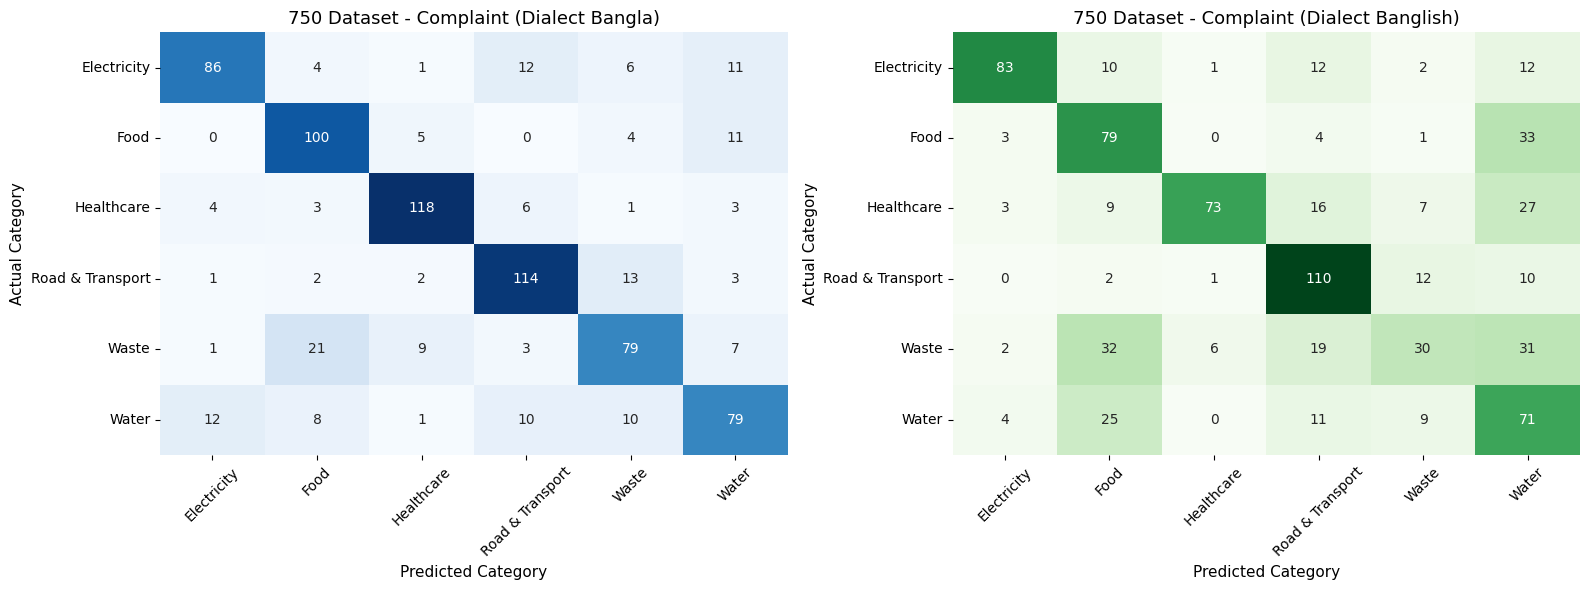

In [19]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Load your fine-tuned mDeBERTa model and tokenizer
model_path = "/content/fine_tuned_mdeberta_grievance"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path).to(device)
model.eval()

id2label = model.config.id2label
classes = sorted([id2label[i] for i in id2label.keys()])

# 2. Load the 750 dialect dataset
df_750 = pd.read_csv('/content/750complaint_dialect - New_Dialect_Complaints_250_Set3.csv')
df_750 = df_750.dropna(subset=['Dialect', 'Category']) # Clean any potential empty rows
y_true = df_750['Category'].astype(str).str.strip().tolist()

# 3. Helper function for batched inference
def run_batch_inference(text_column):
    texts = df_750[text_column].astype(str).tolist()
    predictions = []
    BATCH_SIZE = 32

    for i in range(0, len(texts), BATCH_SIZE):
        batch_texts = texts[i:i + BATCH_SIZE]
        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            outputs = model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)
            preds = torch.argmax(probs, dim=-1).cpu().tolist()

        predictions.extend([id2label[p] for p in preds])
    return predictions

# 4. Run inference on both Bangla and Banglish script variants
print("Running inference on 750 dataset (Dialect Bangla)...")
bangla_preds = run_batch_inference('Complaint (Dialect Bangla)')

print("Running inference on 750 dataset (Dialect Banglish)...")
banglish_preds = run_batch_inference('Complaint (Dialect Banglish)')

# 5. Print Performance Metrics Comparison
print(f"\n{'='*20} 750 DATASET PERFORMANCE COMPARISON {'='*20}")
print(f"Bangla Script   -> Accuracy: {accuracy_score(y_true, bangla_preds):.4f} | F1-Macro: {f1_score(y_true, bangla_preds, average='macro'):.4f}")
print(f"Banglish Script -> Accuracy: {accuracy_score(y_true, banglish_preds):.4f} | F1-Macro: {f1_score(y_true, banglish_preds, average='macro'):.4f}")

# Detailed Classification Report for Banglish (or Bangla)
print("\n--- Classification Report (Banglish Script) ---")
print(classification_report(y_true, banglish_preds, zero_division=0))

# 6. Plot Side-by-Side Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_bangla = confusion_matrix(y_true, bangla_preds, labels=classes)
sns.heatmap(cm_bangla, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title("750 Dataset - Complaint (Dialect Bangla)", fontsize=13)
axes[0].set_xlabel("Predicted Category", fontsize=11)
axes[0].set_ylabel("Actual Category", fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

cm_banglish = confusion_matrix(y_true, banglish_preds, labels=classes)
sns.heatmap(cm_banglish, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Greens', cbar=False, ax=axes[1])
axes[1].set_title("750 Dataset - Complaint (Dialect Banglish)", fontsize=13)
axes[1].set_xlabel("Predicted Category", fontsize=11)
axes[1].set_ylabel("Actual Category", fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

✅ SVM pipeline loaded successfully from disk!

==================== SVM PERFORMANCE ON 750 DIALECT DATASET ====================
Banglish Script -> Accuracy: 0.7067 | F1-Macro: 0.7032
Bangla Script   -> Accuracy: 0.5067 | F1-Macro: 0.5050

--- Classification Report (SVM on Banglish Script) ---
                  precision    recall  f1-score   support

     Electricity       0.74      0.72      0.73       120
            Food       0.67      0.74      0.71       120
      Healthcare       0.81      0.72      0.76       135
Road & Transport       0.73      0.79      0.75       135
           Waste       0.67      0.74      0.71       120
           Water       0.61      0.53      0.56       120

        accuracy                           0.71       750
       macro avg       0.70      0.70      0.70       750
    weighted avg       0.71      0.71      0.71       750



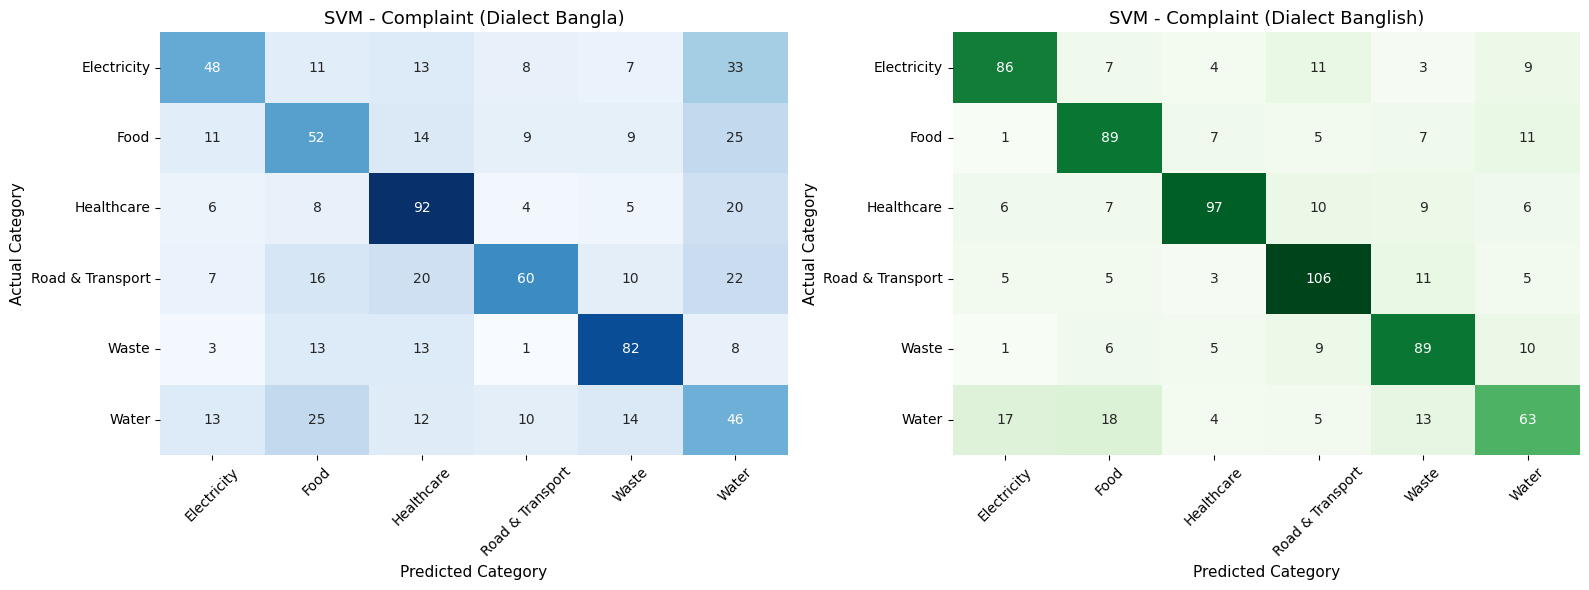

In [20]:
import joblib
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the saved Multilingual SVM Pipeline
svm_model_path = '/content/multilingual_grievance_svm_pipeline.pkl'
try:
    svm_pipeline = joblib.load(svm_model_path)
    print("✅ SVM pipeline loaded successfully from disk!")
except Exception as e:
    print(f"❌ Could not load SVM pipeline: {e}. Please ensure you ran the SVM training cell earlier.")

# 2. Load the 750 dialect complaints dataset
df_750 = pd.read_csv('/content/750complaint_dialect - New_Dialect_Complaints_250_Set3.csv')
df_750 = df_750.dropna(subset=['Dialect', 'Category']) # Clean stray empty rows

y_true = df_750['Category'].astype(str).str.strip().tolist()
classes = sorted(list(set(y_true)))

# 3. Test on both Banglish and Bangla text columns
texts_banglish = df_750['Complaint (Dialect Banglish)'].astype(str).tolist()
texts_bangla = df_750['Complaint (Dialect Bangla)'].astype(str).tolist()

preds_banglish = svm_pipeline.predict(texts_banglish)
preds_bangla = svm_pipeline.predict(texts_bangla)

# 4. Print Overall Metrics Comparison
print(f"\n{'='*20} SVM PERFORMANCE ON 750 DIALECT DATASET {'='*20}")
print(f"Banglish Script -> Accuracy: {accuracy_score(y_true, preds_banglish):.4f} | F1-Macro: {f1_score(y_true, preds_banglish, average='macro'):.4f}")
print(f"Bangla Script   -> Accuracy: {accuracy_score(y_true, preds_bangla):.4f} | F1-Macro: {f1_score(y_true, preds_bangla, average='macro'):.4f}")

# Detailed Classification Report for Banglish Script
print("\n--- Classification Report (SVM on Banglish Script) ---")
print(classification_report(y_true, preds_banglish, zero_division=0))

# 5. Plot Side-by-Side Confusion Matrices for SVM
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_bangla = confusion_matrix(y_true, preds_bangla, labels=classes)
sns.heatmap(cm_bangla, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title("SVM - Complaint (Dialect Bangla)", fontsize=13)
axes[0].set_xlabel("Predicted Category", fontsize=11)
axes[0].set_ylabel("Actual Category", fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

cm_banglish = confusion_matrix(y_true, preds_banglish, labels=classes)
sns.heatmap(cm_banglish, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Greens', cbar=False, ax=axes[1])
axes[1].set_title("SVM - Complaint (Dialect Banglish)", fontsize=13)
axes[1].set_xlabel("Predicted Category", fontsize=11)
axes[1].set_ylabel("Actual Category", fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Using device: cuda
Loading zero-shot model & tokenizer: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


--- Running Zero-Shot Inference on Dialect Bangla ---

--- Running Zero-Shot Inference on Dialect Banglish ---

========================= ZERO-SHOT PERFORMANCE COMPARISON =========================
Bangla Script   -> Accuracy: 0.5707 | F1-Macro: 0.5765
Banglish Script -> Accuracy: 0.3560 | F1-Macro: 0.3616


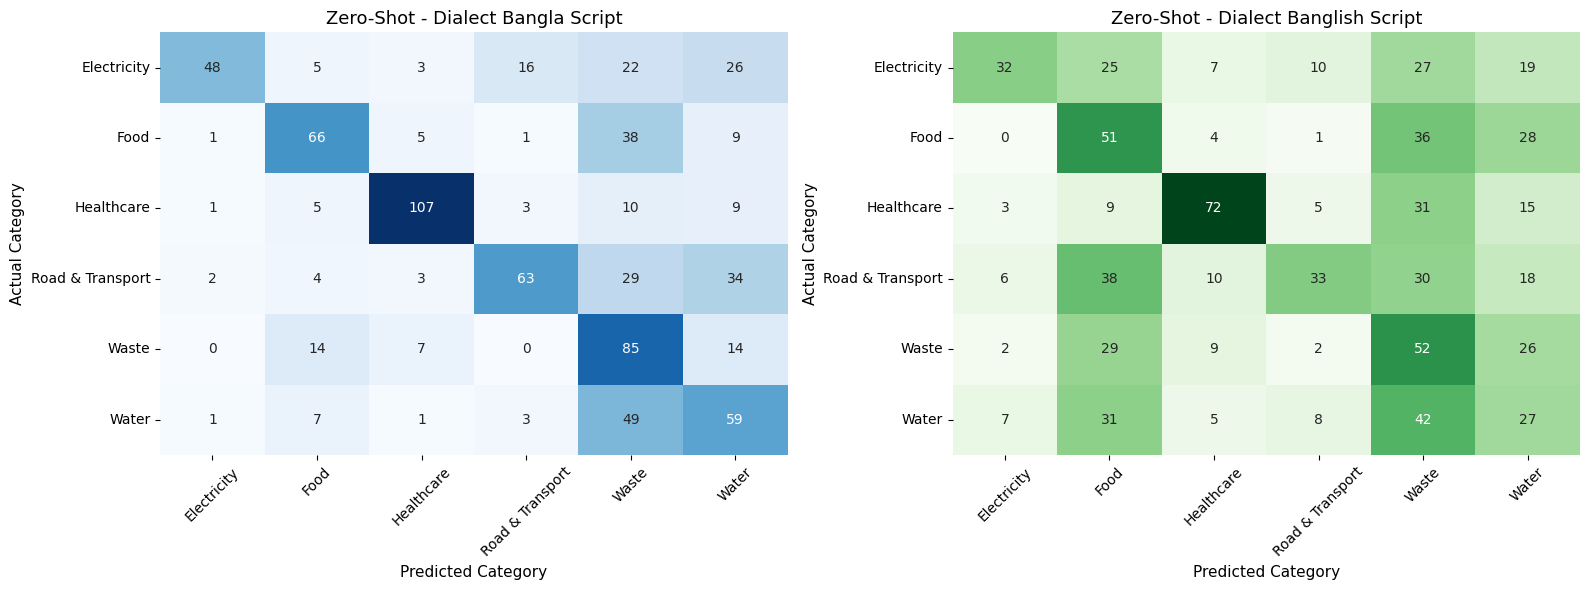

In [21]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Setup Device and Load Zero-Shot NLI Model & Tokenizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model_name = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
print(f"Loading zero-shot model & tokenizer: {model_name}...")
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)
model.eval()

# Identify entailment index
entailment_idx = 2
if hasattr(model.config, "id2label"):
    for idx, label in model.config.id2label.items():
        if label.lower() in ["entailment", "entail"]:
            entailment_idx = idx
            break

# 2. Load the 750 dataset
df_750 = pd.read_csv('/content/750complaint_dialect - New_Dialect_Complaints_250_Set3.csv')
df_750 = df_750.dropna(subset=['Dialect', 'Category'])

y_true_all = df_750['Category'].astype(str).str.strip().tolist()
target_labels = sorted(list(set(y_true_all)))
hypothesis_template = "This text is about {}."

# 3. Batched Zero-Shot Inference Function
def batch_zero_shot_predict(text_batch, batch_size=32):
    all_preds = []
    for i in range(0, len(text_batch), batch_size):
        sub_texts = text_batch[i:i + batch_size]
        batch_pairs = []

        for text in sub_texts:
            clean_text = text if text and isinstance(text, str) and text.strip() else "Unknown complaint"
            for label in target_labels:
                batch_pairs.append([clean_text, hypothesis_template.format(label)])

        inputs = tokenizer(
            batch_pairs,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            outputs = model(**inputs)
            logits = outputs.logits

        probs = F.softmax(logits, dim=-1)
        entailment_scores = probs[:, entailment_idx].cpu().numpy()
        entailment_scores = entailment_scores.reshape(len(sub_texts), len(target_labels))

        best_label_indices = np.argmax(entailment_scores, axis=1)
        for idx in best_label_indices:
            all_preds.append(target_labels[idx])

    return all_preds

# 4. Run Inference on Both Scripts Separately
print("\n--- Running Zero-Shot Inference on Dialect Bangla ---")
texts_bangla = df_750['Complaint (Dialect Bangla)'].astype(str).tolist()
preds_bangla = batch_zero_shot_predict(texts_bangla, batch_size=32)

print("\n--- Running Zero-Shot Inference on Dialect Banglish ---")
texts_banglish = df_750['Complaint (Dialect Banglish)'].astype(str).tolist()
preds_banglish = batch_zero_shot_predict(texts_banglish, batch_size=32)

# 5. Print Performance Metrics Comparison
print(f"\n{'='*25} ZERO-SHOT PERFORMANCE COMPARISON {'='*25}")
print(f"Bangla Script   -> Accuracy: {accuracy_score(y_true_all, preds_bangla):.4f} | F1-Macro: {f1_score(y_true_all, preds_bangla, average='macro'):.4f}")
print(f"Banglish Script -> Accuracy: {accuracy_score(y_true_all, preds_banglish):.4f} | F1-Macro: {f1_score(y_true_all, preds_banglish, average='macro'):.4f}")

# 6. Plot Side-by-Side Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_bangla = confusion_matrix(y_true_all, preds_bangla, labels=target_labels)
sns.heatmap(cm_bangla, annot=True, fmt='d', xticklabels=target_labels, yticklabels=target_labels, cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title("Zero-Shot - Dialect Bangla Script", fontsize=13)
axes[0].set_xlabel("Predicted Category", fontsize=11)
axes[0].set_ylabel("Actual Category", fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

cm_banglish = confusion_matrix(y_true_all, preds_banglish, labels=target_labels)
sns.heatmap(cm_banglish, annot=True, fmt='d', xticklabels=target_labels, yticklabels=target_labels, cmap='Greens', cbar=False, ax=axes[1])
axes[1].set_title("Zero-Shot - Dialect Banglish Script", fontsize=13)
axes[1].set_xlabel("Predicted Category", fontsize=11)
axes[1].set_ylabel("Actual Category", fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

✅ SVM pipeline loaded successfully from disk!

=== SVM DIALECT-WISE PERFORMANCE SUMMARY ===


,Dialect Region,Sample Count,Accuracy,Macro F1-Score
0,Barishal,150,0.706667,0.706974
1,Chittagong,150,0.713333,0.712088
2,Mymensingh,150,0.760000,0.761604
3,Noakhali,150,0.693333,0.671951
4,Sylhet,150,0.660000,0.633948


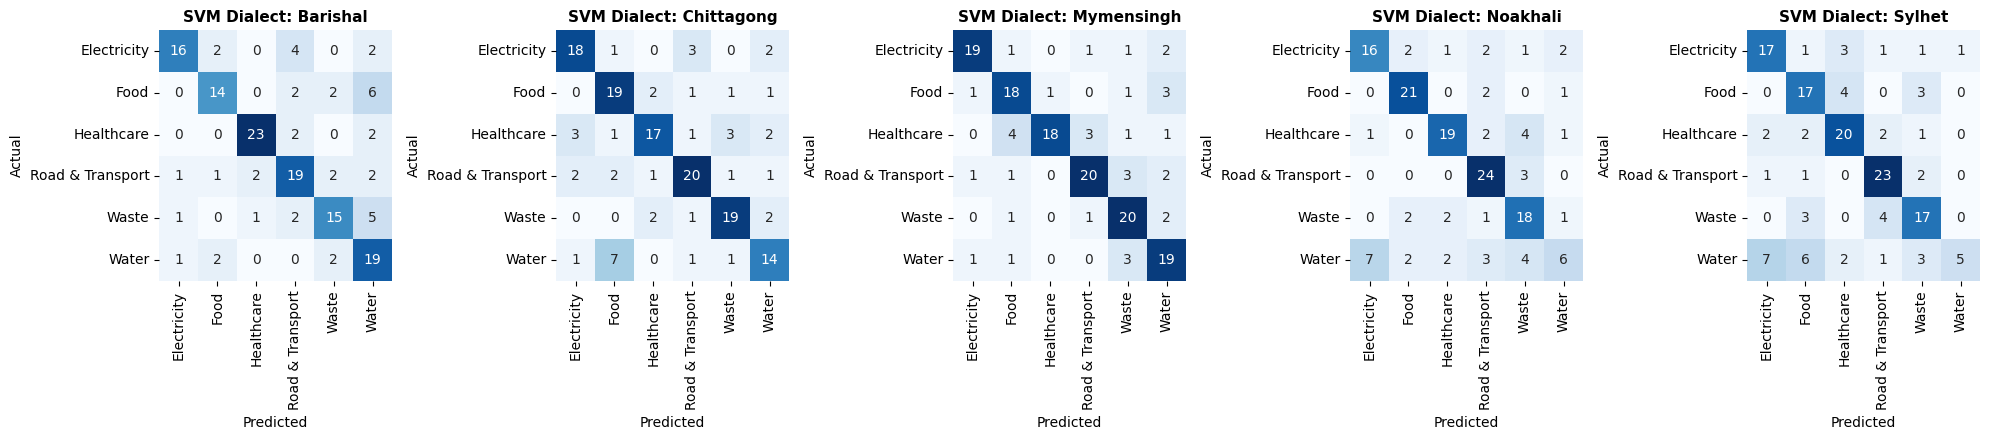

In [22]:
import joblib
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the saved Multilingual SVM Pipeline
svm_model_path = '/content/multilingual_grievance_svm_pipeline.pkl'
try:
    svm_pipeline = joblib.load(svm_model_path)
    print("✅ SVM pipeline loaded successfully from disk!")
except Exception as e:
    print(f"❌ Could not load SVM pipeline: {e}. Please ensure you ran the SVM training cell earlier.")

# 2. Load the 750 dialect dataset
df_750 = pd.read_csv('/content/750complaint_dialect - New_Dialect_Complaints_250_Set3.csv')
df_750 = df_750.dropna(subset=['Dialect', 'Category']) # Clean any stray empty rows

target_labels = sorted(df_750['Category'].astype(str).str.strip().unique())
dialects = sorted(df_750['Dialect'].astype(str).str.strip().unique())

# Choose text column ('Complaint (Dialect Banglish)' or 'Complaint (Dialect Bangla)')
text_col = 'Complaint (Dialect Banglish)'
texts = df_750[text_col].astype(str).tolist()

# 3. Run predictions on the whole dataset using SVM
df_750['SVM_Predicted_Category'] = svm_pipeline.predict(texts)

# 4. Compute Dialect-Wise Metrics Summary Table
regional_metrics = []
for dialect in dialects:
    sub_df = df_750[df_750['Dialect'] == dialect]
    d_true = sub_df['Category'].astype(str).str.strip().tolist()
    d_pred = sub_df['SVM_Predicted_Category'].tolist()

    acc = accuracy_score(d_true, d_pred)
    f1 = f1_score(d_true, d_pred, average='macro', zero_division=0)

    regional_metrics.append({
        'Dialect Region': dialect,
        'Sample Count': len(sub_df),
        'Accuracy': acc,
        'Macro F1-Score': f1
    })

df_metrics_summary = pd.DataFrame(regional_metrics)
print("\n=== SVM DIALECT-WISE PERFORMANCE SUMMARY ===")
display(df_metrics_summary)

# 5. Plot Side-by-Side Confusion Matrices for each of the 5 Dialect Regions
fig, axes = plt.subplots(1, len(dialects), figsize=(4 * len(dialects), 4.5))

for idx, dialect in enumerate(dialects):
    sub_df = df_750[df_750['Dialect'] == dialect]
    cm = confusion_matrix(sub_df['Category'], sub_df['SVM_Predicted_Category'], labels=target_labels)

    sns.heatmap(
        cm, annot=True, fmt='d', xticklabels=target_labels, yticklabels=target_labels,
        cmap='Blues', cbar=False, ax=axes[idx]
    )
    axes[idx].set_title(f"SVM Dialect: {dialect}", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Predicted", fontsize=10)
    axes[idx].set_ylabel("Actual", fontsize=10)
    axes[idx].tick_params(axis='x', rotation=90)
    axes[idx].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

Using device: cuda
Loading zero-shot model & tokenizer: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Running zero-shot predictions on 750 dialect dataset...

=== ZERO-SHOT DIALECT-WISE PERFORMANCE SUMMARY ===


,Dialect Region,Sample Count,Accuracy,Macro F1-Score
0,Barishal,150,0.360000,0.368582
1,Chittagong,150,0.366667,0.376044
2,Mymensingh,150,0.353333,0.350801
3,Noakhali,150,0.340000,0.342776
4,Sylhet,150,0.360000,0.363203


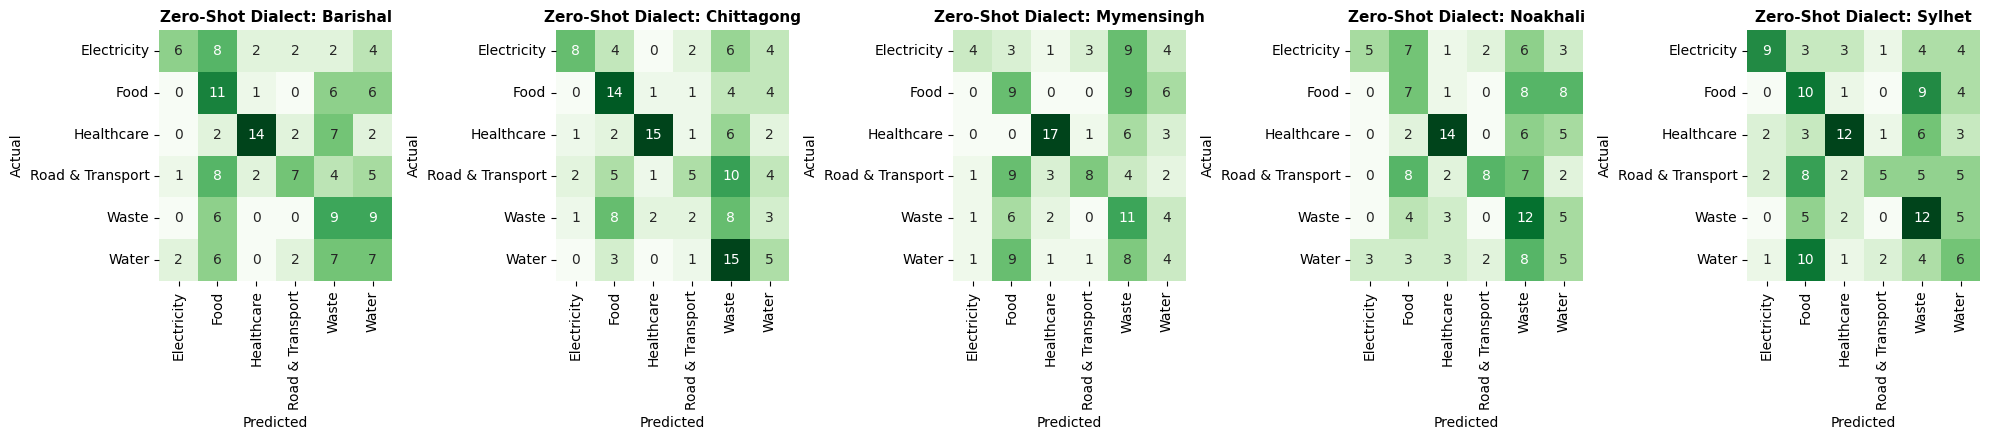

In [23]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Setup Device and Load Zero-Shot NLI Model & Tokenizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model_name = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
print(f"Loading zero-shot model & tokenizer: {model_name}...")
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)
model.eval()

# Identify entailment index
entailment_idx = 2
if hasattr(model.config, "id2label"):
    for idx, label in model.config.id2label.items():
        if label.lower() in ["entailment", "entail"]:
            entailment_idx = idx
            break

# 2. Load the 750 dialect dataset
df_750 = pd.read_csv('/content/750complaint_dialect - New_Dialect_Complaints_250_Set3.csv')
df_750 = df_750.dropna(subset=['Dialect', 'Category']) # Clean any stray empty rows

target_labels = sorted(df_750['Category'].astype(str).str.strip().unique())
dialects = sorted(df_750['Dialect'].astype(str).str.strip().unique())
hypothesis_template = "This text is about {}."

# Choose text column ('Complaint (Dialect Banglish)' or 'Complaint (Dialect Bangla)')
text_col = 'Complaint (Dialect Banglish)'
texts = df_750[text_col].astype(str).tolist()

# 3. Batched Zero-Shot Inference Function
def batch_zero_shot_predict(text_batch, batch_size=32):
    all_preds = []
    for i in range(0, len(text_batch), batch_size):
        sub_texts = text_batch[i:i + batch_size]
        batch_pairs = []

        for text in sub_texts:
            clean_text = text if text and isinstance(text, str) and text.strip() else "Unknown complaint"
            for label in target_labels:
                batch_pairs.append([clean_text, hypothesis_template.format(label)])

        inputs = tokenizer(
            batch_pairs,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            outputs = model(**inputs)
            logits = outputs.logits

        probs = F.softmax(logits, dim=-1)
        entailment_scores = probs[:, entailment_idx].cpu().numpy()
        entailment_scores = entailment_scores.reshape(len(sub_texts), len(target_labels))

        best_label_indices = np.argmax(entailment_scores, axis=1)
        for idx in best_label_indices:
            all_preds.append(target_labels[idx])

    return all_preds

# 4. Run zero-shot predictions across the dataset
print("Running zero-shot predictions on 750 dialect dataset...")
df_750['ZeroShot_Predicted_Category'] = batch_zero_shot_predict(texts, batch_size=32)

# 5. Compute Dialect-Wise Metrics Summary Table
regional_metrics = []
for dialect in dialects:
    sub_df = df_750[df_750['Dialect'] == dialect]
    d_true = sub_df['Category'].astype(str).str.strip().tolist()
    d_pred = sub_df['ZeroShot_Predicted_Category'].tolist()

    acc = accuracy_score(d_true, d_pred)
    f1 = f1_score(d_true, d_pred, average='macro', zero_division=0)

    regional_metrics.append({
        'Dialect Region': dialect,
        'Sample Count': len(sub_df),
        'Accuracy': acc,
        'Macro F1-Score': f1
    })

df_metrics_summary = pd.DataFrame(regional_metrics)
print("\n=== ZERO-SHOT DIALECT-WISE PERFORMANCE SUMMARY ===")
display(df_metrics_summary)

# 6. Plot Side-by-Side Confusion Matrices for each of the 5 Dialect Regions
fig, axes = plt.subplots(1, len(dialects), figsize=(4 * len(dialects), 4.5))

for idx, dialect in enumerate(dialects):
    sub_df = df_750[df_750['Dialect'] == dialect]
    cm = confusion_matrix(sub_df['Category'], sub_df['ZeroShot_Predicted_Category'], labels=target_labels)

    sns.heatmap(
        cm, annot=True, fmt='d', xticklabels=target_labels, yticklabels=target_labels,
        cmap='Greens', cbar=False, ax=axes[idx]
    )
    axes[idx].set_title(f"Zero-Shot Dialect: {dialect}", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Predicted", fontsize=10)
    axes[idx].set_ylabel("Actual", fontsize=10)
    axes[idx].tick_params(axis='x', rotation=90)
    axes[idx].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

In [39]:
import torch
import pandas as pd
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score

# ==========================================
# 1. LOAD TRAINING & TEST SETS DIRECTLY
# ==========================================
train_df = pd.read_csv('/content/500complaint_dialect - New_Dialect_Complaints_250_Set3.csv').dropna(subset=['Dialect', 'Category'])
test_df = pd.read_csv('/content/250testSet - New_Dialect_Complaints_250_Set2 - New_Dialect_Complaints_250_Set2 (1).csv.csv').dropna(subset=['Dialect', 'Category'])

print(f"✅ Training Samples: {len(train_df)} | Test Samples: {len(test_df)}")

# Map Categories to Integer IDs consistently across both
categories = sorted(train_df['Category'].astype(str).str.strip().unique())
label2id = {label: i for i, label in enumerate(categories)}
id2label = {i: label for i, label in enumerate(categories)}

train_df['label'] = train_df['Category'].map(label2id)
test_df['label'] = test_df['Category'].map(label2id)

# ==========================================
# 2. LOAD TOKENIZER & MODEL (FULL FP32 PRECISION)
# ==========================================
model_ckpt = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)

model = AutoModelForSequenceClassification.from_pretrained(
    model_ckpt,
    num_labels=len(categories),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

# Ensure full precision to bypass T4 GradScaler FP16 unscaling errors
model.to(torch.float32)

# ==========================================
# 3. PREPARE HUGGINGFACE DATASETS
# ==========================================
text_column = 'Complaint (Dialect Banglish)'

train_dataset = Dataset.from_pandas(train_df[['label', text_column]].rename(columns={text_column: 'text'}))
test_dataset = Dataset.from_pandas(test_df[['label', text_column]].rename(columns={text_column: 'text'}))

def tokenize_function(examples):
    return tokenizer(examples['text'], padding="max_length", truncation=True, max_length=128)

train_tokenized = train_dataset.map(tokenize_function, batched=True)
test_tokenized = test_dataset.map(tokenize_function, batched=True)

# ==========================================
# 4. DEFINE TRAINING ARGUMENTS & TRAINER
# ==========================================
training_args = TrainingArguments(
    output_dir="./dialect_finetuned_mdeberta",
    learning_rate=4e-5,          # Slightly higher for small dataset
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=7,          # Increased from 3 to 7 epochs
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    fp16=False,
    logging_steps=10
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, average='macro')
    return {"accuracy": acc, "f1_macro": f1}

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=test_tokenized,
    compute_metrics=compute_metrics
)

# ==========================================
# 5. EXECUTE FINE-TUNING & EVALUATION
# ==========================================
print("\n🚀 Starting Fine-Tuning on 500 Regional Dialect Samples...")
trainer.train()

# Save the trained model
model.save_pretrained("/content/dialect_finetuned_mdeberta_model")
tokenizer.save_pretrained("/content/dialect_finetuned_mdeberta_model")
print("\n✅ Fine-Tuning Complete! Model saved successfully.")

# Evaluate on the 250 test set
eval_results = trainer.evaluate()
print("\n=== FINAL EVALUATION ON 250 DIALECT TEST SET ===")
print(f"Accuracy: {eval_results['eval_accuracy']:.4f}")
print(f"Macro F1-Score: {eval_results['eval_f1_macro']:.4f}")

✅ Training Samples: 500 | Test Samples: 250


[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `3`.


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([3]) vs model:torch.Size([6])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([3, 768]) vs model:torch.Size([6, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/250 [00:00<?, ? examples/s]

... (9 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


✅ Fine-Tuning Complete! Model saved successfully.


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.642525,1.078980,7,0.680000,0.672106



=== FINAL EVALUATION ON 250 DIALECT TEST SET ===
Accuracy: 0.6800
Macro F1-Score: 0.6721


Loading fine-tuned model from /content/dialect_finetuned_mdeberta_model...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Running batch inference on the 250 test set...

🎯 Fine-Tuned Test Accuracy: 0.6800
🎯 Fine-Tuned Macro F1-Score: 0.6721

--- Detailed Classification Report ---
                  precision    recall  f1-score   support

     Electricity       0.58      0.82      0.68        40
            Food       0.60      0.68      0.64        40
      Healthcare       0.80      0.73      0.77        45
Road & Transport       0.93      0.84      0.88        45
           Waste       0.76      0.40      0.52        40
           Water       0.51      0.57      0.54        40

        accuracy                           0.68       250
       macro avg       0.70      0.68      0.67       250
    weighted avg       0.70      0.68      0.68       250



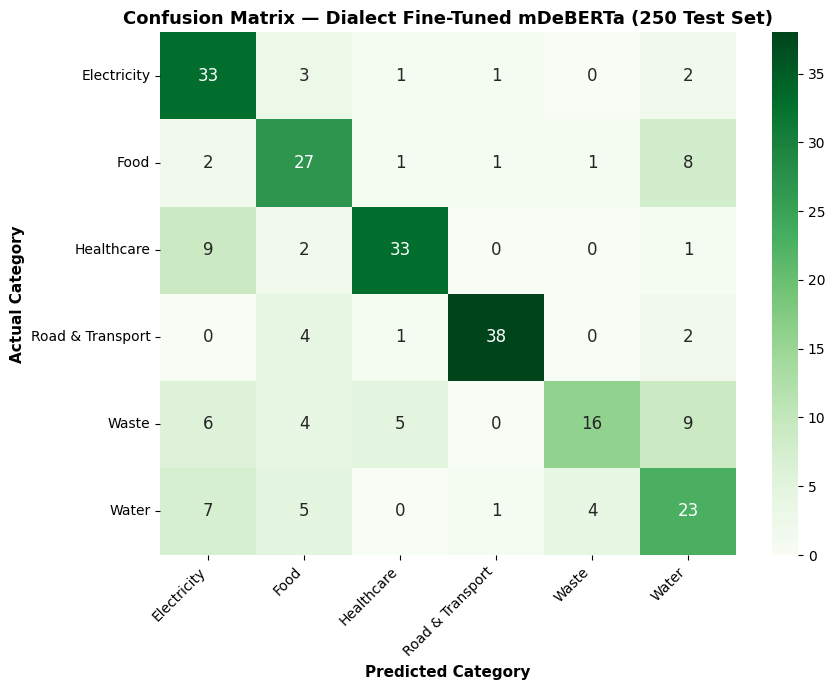

In [40]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Setup Device and Load the Fine-Tuned Model & Tokenizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_path = "/content/dialect_finetuned_mdeberta_model"

print(f"Loading fine-tuned model from {model_path}...")
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path).to(device)
model.eval()

id2label = model.config.id2label
classes = sorted([id2label[i] for i in id2label.keys()])

# 2. Load the 250 Test Set
test_df = pd.read_csv('/content/250testSet - New_Dialect_Complaints_250_Set2 - New_Dialect_Complaints_250_Set2 (1).csv.csv').dropna(subset=['Dialect', 'Category'])
y_true = test_df['Category'].astype(str).str.strip().tolist()
texts = test_df['Complaint (Dialect Banglish)'].astype(str).tolist()

# 3. Run Batched Inference on the Test Set
predictions = []
BATCH_SIZE = 32

print("Running batch inference on the 250 test set...")
for i in range(0, len(texts), BATCH_SIZE):
    batch_texts = texts[i:i + BATCH_SIZE]
    inputs = tokenizer(
        batch_texts,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = F.softmax(outputs.logits, dim=-1)
        preds = torch.argmax(probs, dim=-1).cpu().tolist()

    predictions.extend([id2label[p] for p in preds])

test_df['Predicted_Category'] = predictions

# 4. Compute Accuracy & Macro F1-Score
acc = accuracy_score(y_true, predictions)
f1 = f1_score(y_true, predictions, average='macro')

print(f"\n🎯 Fine-Tuned Test Accuracy: {acc:.4f}")
print(f"🎯 Fine-Tuned Macro F1-Score: {f1:.4f}")

# Detailed Classification Report
print("\n--- Detailed Classification Report ---")
print(classification_report(y_true, predictions, zero_division=0))

# 5. Plot Confusion Matrix Heatmap
cm = confusion_matrix(y_true, predictions, labels=classes)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes,
    cmap='Greens', cbar=True, annot_kws={"size": 12}
)
plt.title("Confusion Matrix — Dialect Fine-Tuned mDeBERTa (250 Test Set)", fontsize=13, fontweight='bold')
plt.xlabel("Predicted Category", fontsize=11, fontweight='bold')
plt.ylabel("Actual Category", fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Loading fine-tuned model from /content/dialect_finetuned_mdeberta_model...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Running batch inference on the 250 test set...

 📍 REGIONAL DIALECT EVALUATION BREAKDOWN 


,Dialect Region,Samples,Accuracy (%),Macro F1 (%)
0,Barishal,50,62.0,61.94
1,Chittagong,50,66.0,64.06
2,Mymensingh,50,70.0,68.73
3,Noakhali,50,70.0,69.63
4,Sylhet,50,72.0,70.68


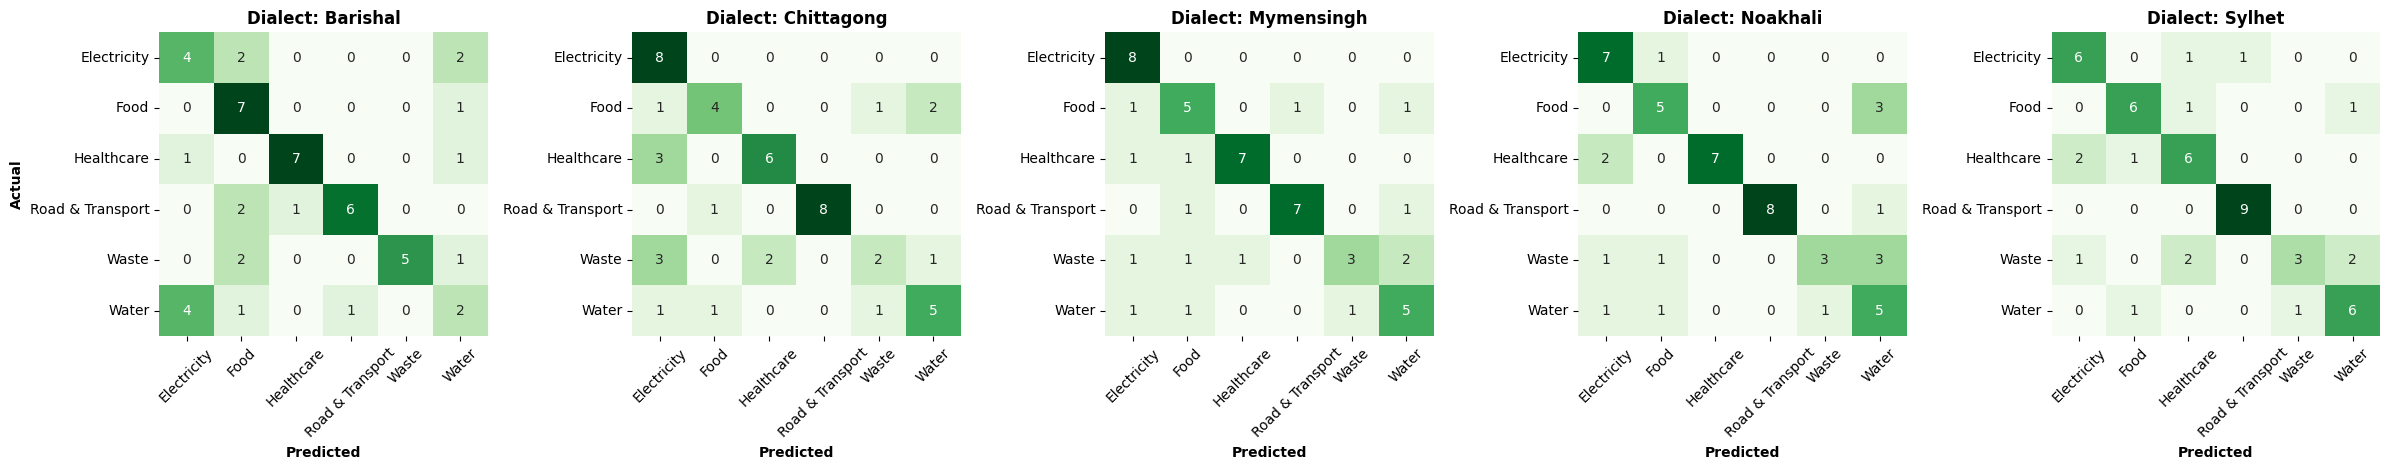

In [42]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Setup Device and Load the Fine-Tuned Model & Tokenizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_path = "/content/dialect_finetuned_mdeberta_model"

print(f"Loading fine-tuned model from {model_path}...")
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path).to(device)
model.eval()

id2label = model.config.id2label
classes = sorted([id2label[i] for i in id2label.keys()])

# 2. Load the 250 Test Set
test_df = pd.read_csv('/content/250testSet - New_Dialect_Complaints_250_Set2 - New_Dialect_Complaints_250_Set2 (1).csv.csv').dropna(subset=['Dialect', 'Category'])
texts = test_df['Complaint (Dialect Banglish)'].astype(str).tolist()

# 3. Run Batched Inference Across All Samples
predictions = []
BATCH_SIZE = 32

print("Running batch inference on the 250 test set...")
for i in range(0, len(texts), BATCH_SIZE):
    batch_texts = texts[i:i + BATCH_SIZE]
    inputs = tokenizer(
        batch_texts,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = F.softmax(outputs.logits, dim=-1)
        preds = torch.argmax(probs, dim=-1).cpu().tolist()

    predictions.extend([id2label[p] for p in preds])

test_df['Predicted_Category'] = predictions

# 4. Dialect-Wise Metrics Summary
dialects = sorted(test_df['Dialect'].astype(str).str.strip().unique())
dialect_summary = []

print("\n" + "="*50)
print(" 📍 REGIONAL DIALECT EVALUATION BREAKDOWN ")
print("="*50)

for d in dialects:
    sub = test_df[test_df['Dialect'] == d]
    d_true = sub['Category'].astype(str).str.strip().tolist()
    d_pred = sub['Predicted_Category'].tolist()

    acc = accuracy_score(d_true, d_pred)
    f1 = f1_score(d_true, d_pred, average='macro', zero_division=0)

    dialect_summary.append({
        'Dialect Region': d,
        'Samples': len(sub),
        'Accuracy (%)': round(acc * 100, 2),
        'Macro F1 (%)': round(f1 * 100, 2)
    })

df_summary = pd.DataFrame(dialect_summary)
display(df_summary)

# 5. Plot 5 Separate Regional Confusion Matrices Side-by-Side
fig, axes = plt.subplots(1, len(dialects), figsize=(4.8 * len(dialects), 4.8))

for idx, d in enumerate(dialects):
    sub = test_df[test_df['Dialect'] == d]
    cm = confusion_matrix(sub['Category'], sub['Predicted_Category'], labels=classes)

    sns.heatmap(
        cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes,
        cmap='Greens', cbar=False, ax=axes[idx], annot_kws={"size": 10}
    )
    axes[idx].set_title(f"Dialect: {d}", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel("Predicted", fontsize=10, fontweight='bold')
    if idx == 0:
        axes[idx].set_ylabel("Actual", fontsize=10, fontweight='bold')
    else:
        axes[idx].set_ylabel("")

    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()